# VAE — LEGEND-200, detector V08682A — lean version

1. **Training**: VAE + classifier for every $\sigma$ window, reconstruction, losses, classifier training.
2. **Working points**: the cut of every method (A/E, VAE ±1$\sigma$, VAE ±3$\sigma$) is set where it keeps `DEP_TARGET` of the DEP **peak** events (background subtracted with a fit).
3. **Classification**: classifier output.
4. **ROC curves**: net survival fractions (from the fits) and ±$k\sigma$ windows, with their tables.
5. **Clustering**: latent space, and waveforms / energy / A/E / rise time of the events where A/E and VAE agree or disagree.

Models already trained (in `BASE_DIR` or `REUSE_DIR`, same events and split) are loaded instead of training again; `RETRAIN = True` trains from scratch.

In [23]:
import os, json, importlib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from scipy.stats import norm
from scipy.ndimage import gaussian_filter1d
from sklearn.metrics import roc_curve
from IPython.display import display

import preliminary as prel
import plotting_functions as pf
import VariationalAutoEncoder as vae

importlib.reload(prel)
importlib.reload(pf)
importlib.reload(vae)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("The device I'm using is:", device)

The device I'm using is: cuda


## CONFIGURATION

In [40]:
# ===================================== DATA =====================================
CHOSEN_DETECTOR = "V08682A"
PERIODS         = [f"p{n:02d}" for n in range(3, 10)]    # p03 ... p09
E_MIN, E_MAX    = 1550, 1650                             # keV
CHECKPOINT_DIR  = "/storage/rasera/clean_data_V08682A"

# =================================== CLEANING ===================================
BASELINE_POINTS     = 300
N_SIGMAS_PEAK       = 3
PRE_TRIGGER_POINTS  = 75       # window = 75 + 124 + 1 = 200 samples
POST_TRIGGER_POINTS = 124
FILTER              = 'gauss'
GAUSS_SIGMA         = 1.25
BUTTER_ORDER        = 4
ALIGNMENT           = 'first'
PROMINENCE_FRACTION = 0.15

# ================================ DEP / FEP FIT =================================
SSE_FIT_WINDOW = (1587, 1598)  # 208Tl DEP
MSE_FIT_WINDOW = (1615, 1626)  # 212Bi FEP

# =================================== VAE RUNS ===================================
SIGMAS       = [1, 3]     # energy windows ±sigma of the SSE / MSE labels: one VAE + classifier each
USE_CHARGE   = False           # False = current only, True = current + charge
CURRENT_MODE = 'scaled'        # 'scaled' = current / median peak of the training set | 'normalised' = peak = 1
RETRAIN      = False           # False: load the models already trained (BASE_DIR, then REUSE_DIR) when possible

# ================================ HYPERPARAMETERS ===============================
BETA          = 1.0
EPOCHS_VAE    = 100
EPOCHS_CLF    = 100
WARMUP        = 10
FREE_BITS     = 0.5
LATENT_DIM    = 8
BATCH_SIZE    = 64
LR_VAE        = 1e-3
LR_CLF        = 1e-3
SEED          = 42
SPLIT_SEED    = 42
TEST_FRACTION = 0.1
VAL_FRACTION  = 0.1

# ================================ WORKING POINTS ================================
DEP_TARGET = 0.90              # net DEP survival fraction of the cuts (A/E recomputed, VAE): 0.92 = official A/E
AOE_HIGH   = 3.0               # A/E cut is double-sided: events with A/E > AOE_HIGH are always rejected (Sec. 2.4 / Ch. 4)
N_THR      = 2000              # thresholds scanned for the net ROC curves
SMOOTH     = 8                 # net ROC curves smoothed over ~SMOOTH thresholds, only for the plot (0 = raw)
TARGETS    = np.round(np.arange(0.80, 1.00, 0.01), 2)   # net DEP SF of the comparison table: 80 ... 99 %

# ================================== EVALUATION ==================================
N_BOOT     = 1000              # bootstrap samples for the AUC errors
FPR_REF    = 0.10              # window ROC: FEP SF compared at 90 % DEP window SF
N_SHOW     = 1000              # max waveforms per panel
RT_BIN     = 16                # ns
N_BINS_AOE = 120

# ==================================== OUTPUT ====================================
PLOTS_DIR = "/storage/rasera/plots"
BASE_DIR  = os.path.join(PLOTS_DIR, f"VAE_plots_DEF_v4_{FILTER}_{ALIGNMENT}")
REUSE_DIR = os.path.join(PLOTS_DIR, f"VAE_plots_DEF_v3_{FILTER}_{ALIGNMENT}")   # None = only BASE_DIR
LEAN_DIR  = os.path.join(BASE_DIR, "lean")                                       # plots of the analysis
os.makedirs(LEAN_DIR, exist_ok=True)

VAE_COLORS = {1: "#2a9d8f", 3: pf.color3}
vae_color = lambda s: VAE_COLORS.get(s, pf.color8)
vae_name  = lambda s: f"VAE classifier trained on ±{s:g}σ"
vae_title = lambda s: rf"VAE classifier trained on ±{s:g}$\sigma$"

# 1. DATA

In [25]:
data = prel.load_data(PERIODS, CHOSEN_DETECTOR, E_MIN, E_MAX, CHECKPOINT_DIR)

clean = prel.preprocess(data, baseline_points=BASELINE_POINTS, n_sigmas=N_SIGMAS_PEAK,
                       pre_trigger_points=PRE_TRIGGER_POINTS, post_trigger_points=POST_TRIGGER_POINTS,
                       filter_type=FILTER, gauss_sigma=GAUSS_SIGMA, butter_order=BUTTER_ORDER,
                       alignment=ALIGNMENT, prominence_fraction=PROMINENCE_FRACTION, keep_steps=False)

fit = prel.fit_peaks(clean['energy'], sse_window=SSE_FIT_WINDOW, mse_window=MSE_FIT_WINDOW)
prel.print_fit(fit)

Period p03: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p04: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p05: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p06: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p07: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p08: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p09: checkpoint loaded from /storage/rasera/clean_data_V08682A
Totale su 7 periodi: 349002 eventi (116985 dopo il taglio A/E)
Waveforms shape (all periods): (349002, 1400)
Energy shape (all periods): (349002,)
A/E shape (all periods): (349002,)
Rise time shape (all periods): (349002,)
Waveforms shape after A/E cut (all periods): (116985, 1400)
Energy shape after A/E cut (all periods): (116985,)
[all events] Kept: 348999 | noise: 3 | edge: 0 | total: 349002
[after A/E cut] Kept: 116984 | noise: 1 | edge: 0 | total: 116985
Filter: Gaussian (sigma = 1.25 samples = 20 ns

# 2. TRAINING: RECONSTRUCTION AND LOSSES
For every $\sigma$ window: reconstruction during the training (only when the VAE is trained now), training / validation losses, reconstruction of a test event, classifier training. The latent means and the classifier output of **every** event are saved in `predictions_*.npz`.

sigma1_current_scaled_beta1  ->  /storage/rasera/plots/VAE_plots_DEF_v4_gauss_first/sigma1/current/scaled


training 64935 | validation 7215 | test 8017 | SSE 28234 | MSE 51933 | scale 0.05572
Loaded trained model: /storage/rasera/plots/VAE_plots_DEF_v4_gauss_first/sigma1/current/scaled/models_sigma1_current_scaled_beta1.pth
Loaded model: the per-epoch reconstruction is not redrawn (snapshots not saved)


/storage/rasera/VAE-v2/plotting_functions.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


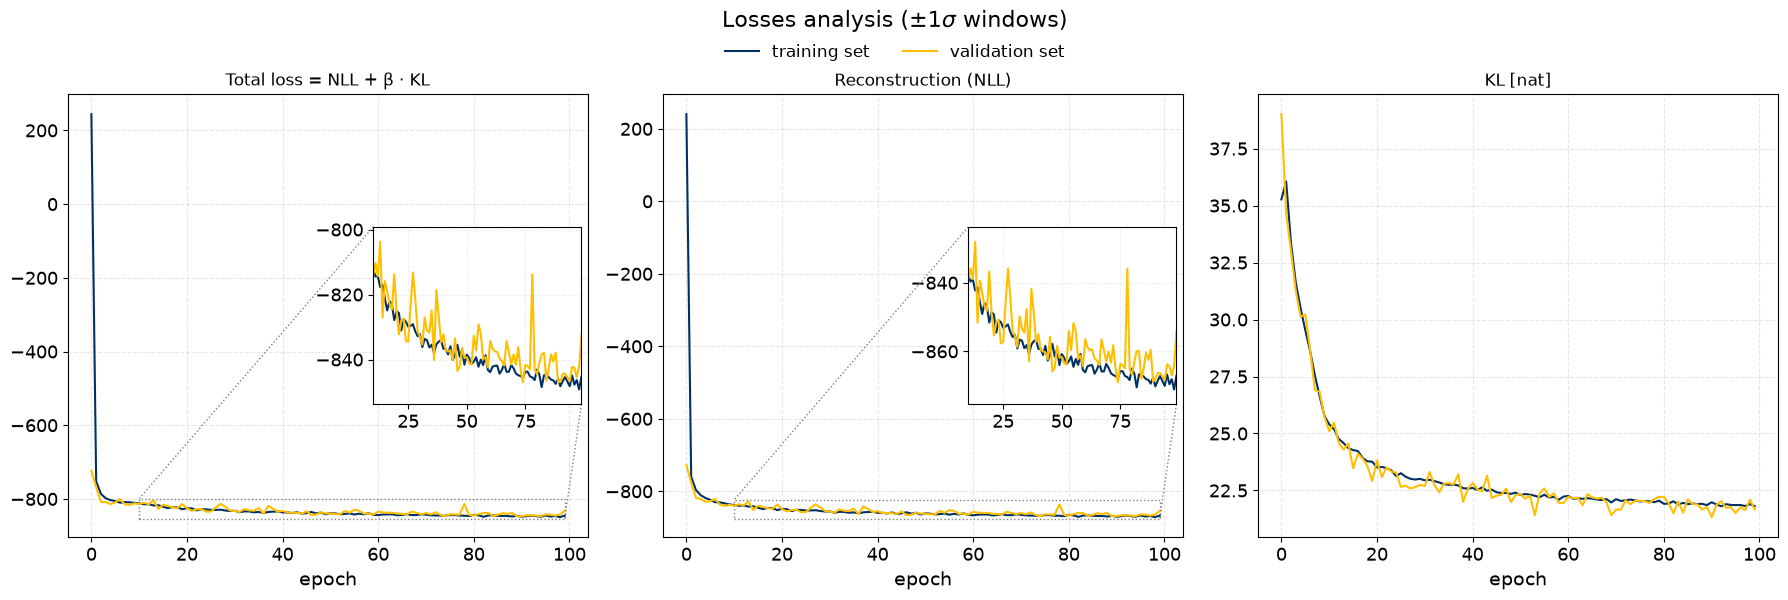

Testing on the device: cuda
Test result - Loss: -832.523772 | Rec: -854.307118 | KL: 21.783344


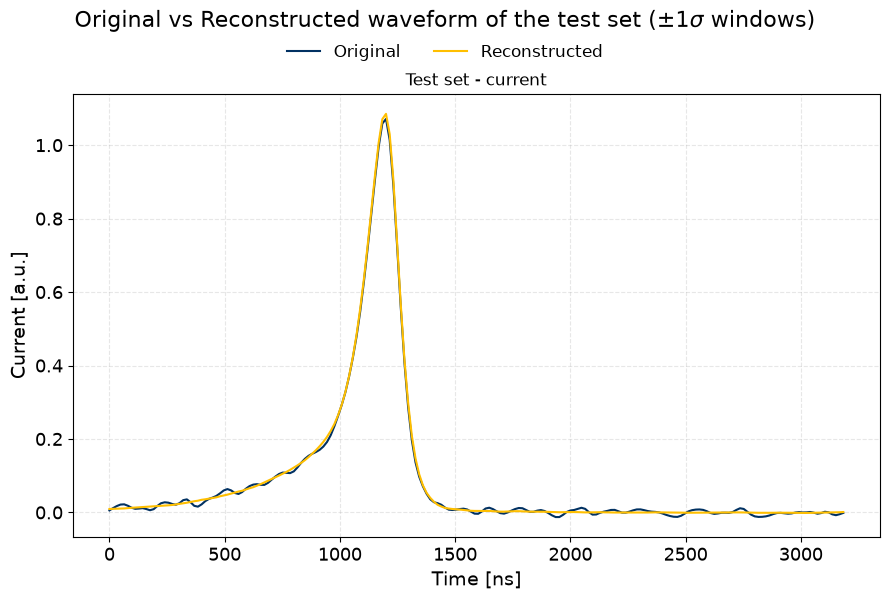

Testing on the device: cuda
Test result - Loss: -838.425241 | Rec: -860.182464 | KL: 21.757224
Classifier test - loss: 0.4777 | accuracy: 78.95%
Testing on the device: cuda
Test result - Loss: -832.535392 | Rec: -854.205744 | KL: 21.670352
Classifier test - loss: 0.4779 | accuracy: 78.66%
Testing on the device: cuda
Test result - Loss: -832.523772 | Rec: -854.307118 | KL: 21.783344
Classifier test - loss: 0.4858 | accuracy: 78.40%


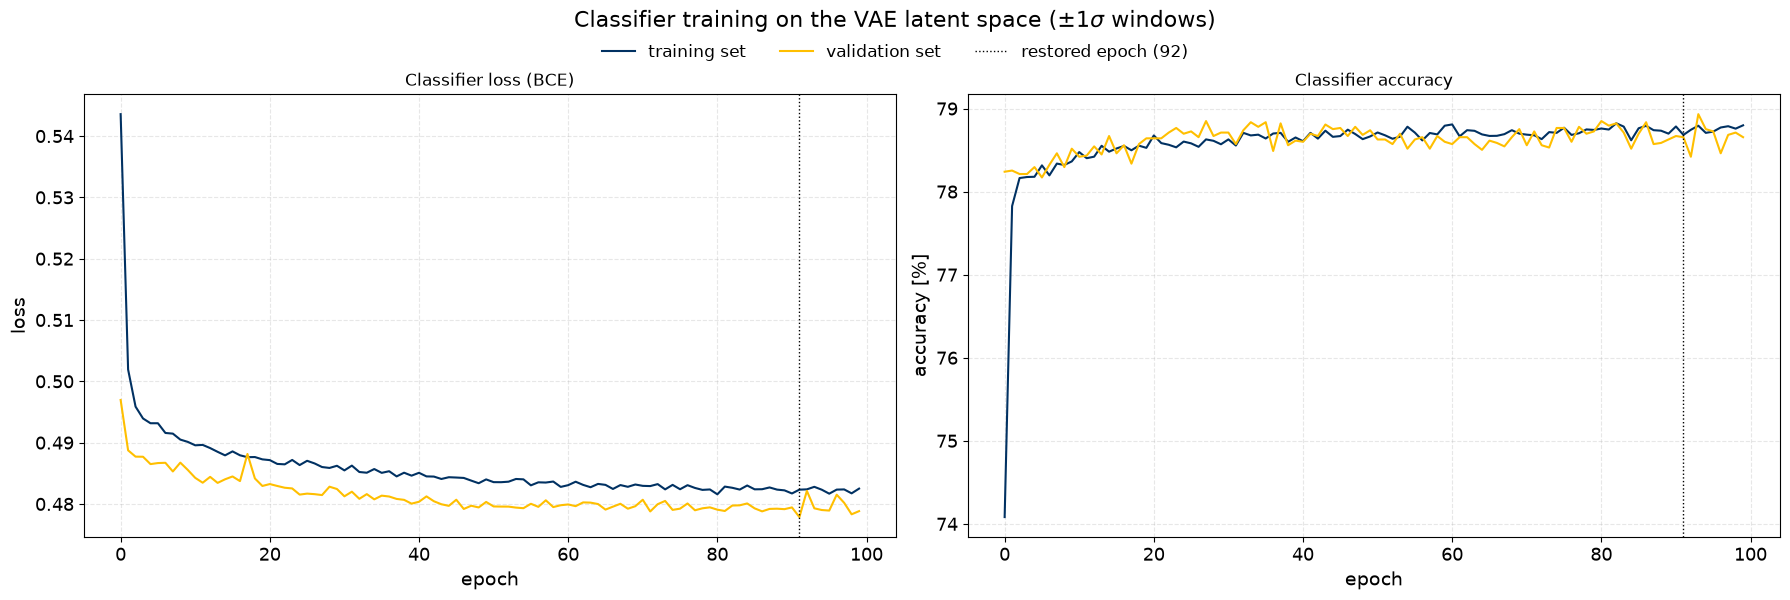

sigma3_current_scaled_beta1  ->  /storage/rasera/plots/VAE_plots_DEF_v4_gauss_first/sigma3/current/scaled
training 125240 | validation 13916 | test 15462 | SSE 59254 | MSE 95364 | scale 0.05605
Loaded trained model: /storage/rasera/plots/VAE_plots_DEF_v4_gauss_first/sigma3/current/scaled/models_sigma3_current_scaled_beta1.pth
Loaded model: the per-epoch reconstruction is not redrawn (snapshots not saved)


/storage/rasera/VAE-v2/plotting_functions.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


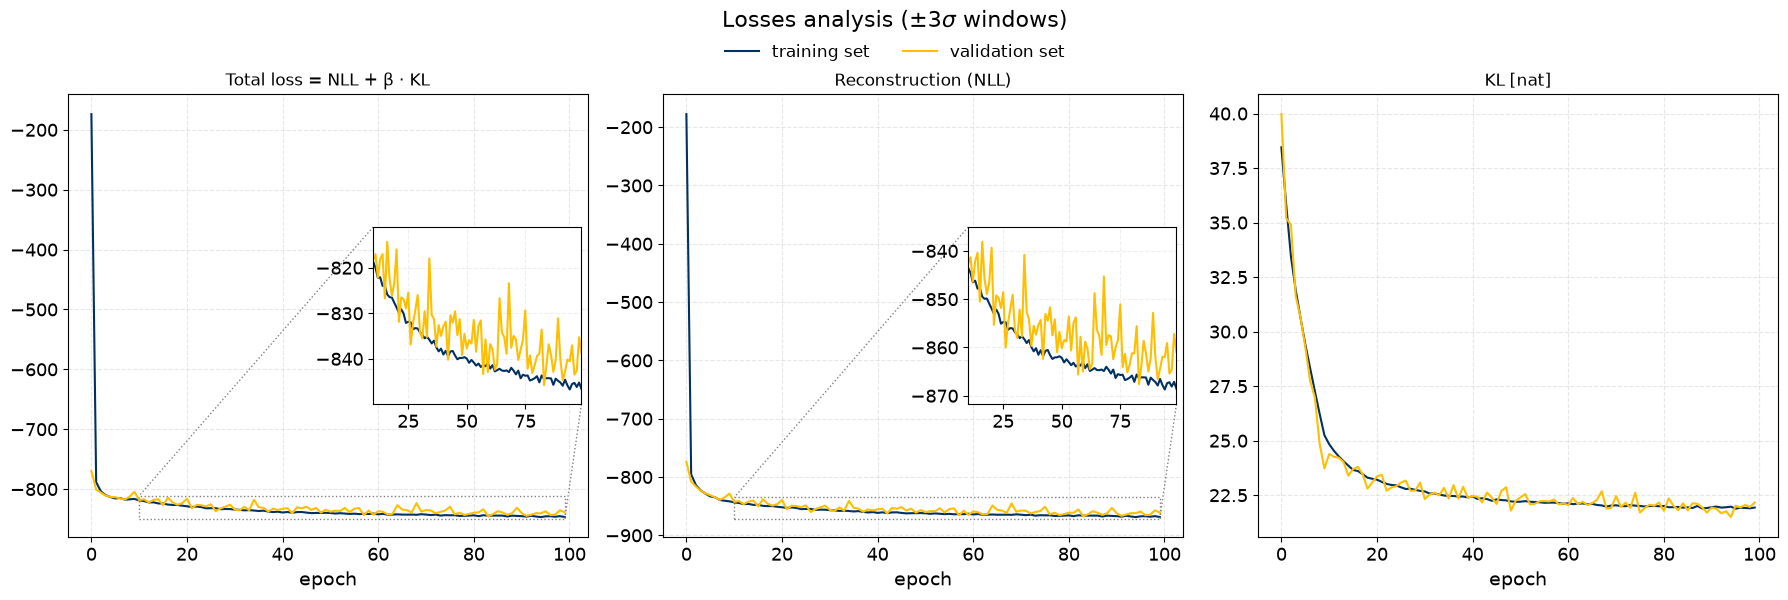

Testing on the device: cuda
Test result - Loss: -839.572190 | Rec: -861.822481 | KL: 22.250290


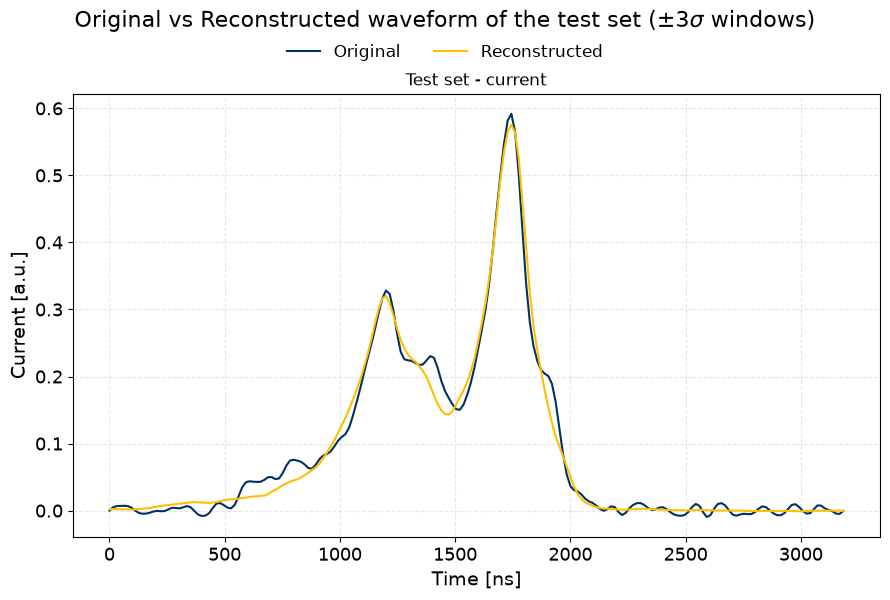

Testing on the device: cuda
Test result - Loss: -845.279521 | Rec: -867.382093 | KL: 22.102573
Classifier test - loss: 0.5654 | accuracy: 72.47%
Testing on the device: cuda
Test result - Loss: -838.763219 | Rec: -860.927759 | KL: 22.164538
Classifier test - loss: 0.5666 | accuracy: 72.62%
Testing on the device: cuda
Test result - Loss: -839.572190 | Rec: -861.822481 | KL: 22.250290
Classifier test - loss: 0.5722 | accuracy: 71.92%


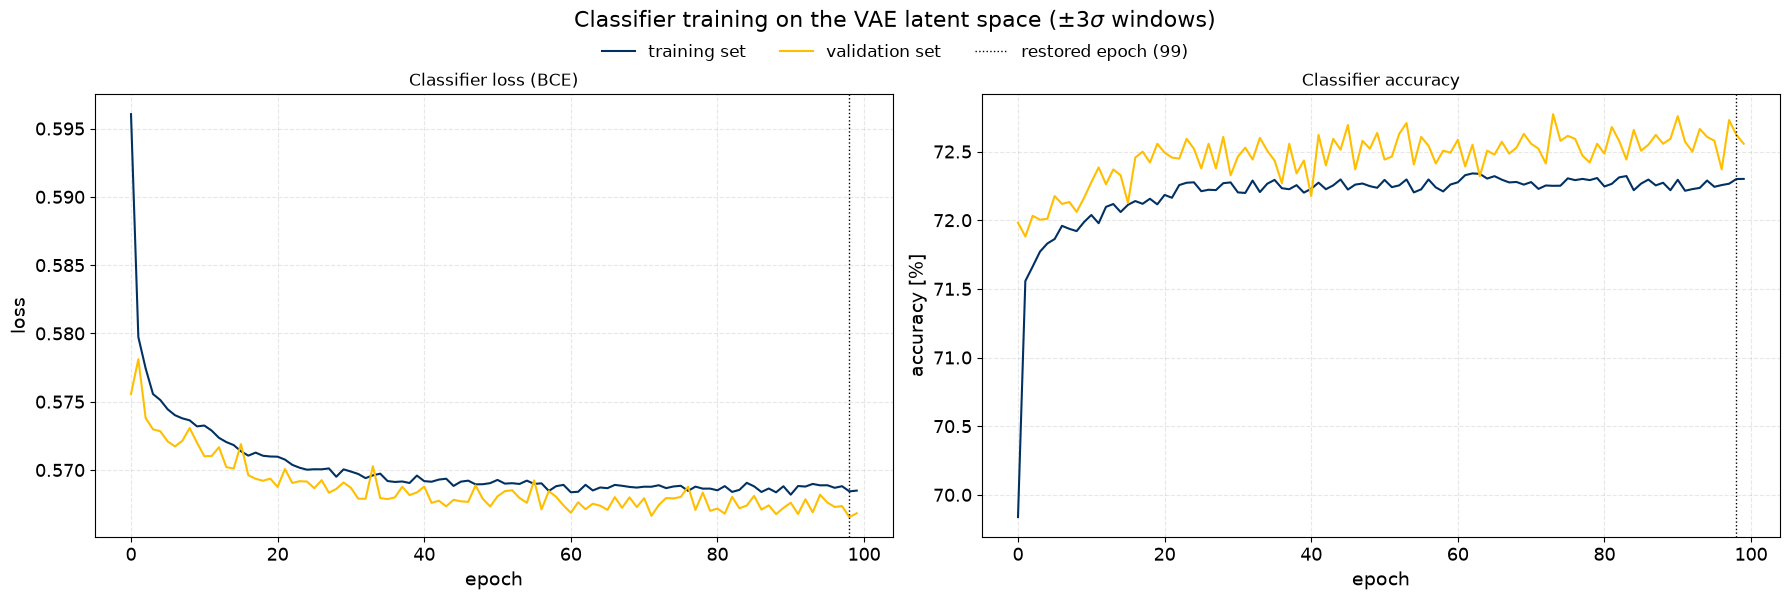

In [41]:
def load_trained(sigma, scale):
    """Model and histories already trained with the same events and split (same scale), else None."""
    tag = prel.run_tag(sigma, USE_CHARGE, CURRENT_MODE, BETA)
    for base in (BASE_DIR, REUSE_DIR):
        if base is None:
            continue
        folder = prel.config_dir(base, sigma, USE_CHARGE, CURRENT_MODE)
        pth, hist = os.path.join(folder, f'models_{tag}.pth'), os.path.join(folder, f'histories_{tag}.json')
        if not (os.path.exists(pth) and os.path.exists(hist)):
            continue
        ckpt = torch.load(pth, map_location='cpu', weights_only=True)
        if not (np.isclose(ckpt['scale'], scale, rtol=1e-6, atol=0) and ckpt.get('latent_dim') == LATENT_DIM
                and ckpt.get('beta') == BETA and ckpt.get('free_bits') == FREE_BITS):
            print(f"{pth}: different scale / latent_dim / beta / free_bits, not reused")
            continue
        with open(hist) as f:
            h = json.load(f)
        print(f'Loaded trained model: {pth}')
        return ckpt, h['vae'], h['classifier']
    return None


def evaluate_losses(model, classifier, d, channels):
    """VAE (loss, NLL, KL) and classifier (BCE, accuracy) of the final models on training, validation and test sets."""
    rows = []
    for name, x, y in (('training set', d['waves_train'], d['labels_train']),
                       ('validation set', d['waves_val'], d['labels_val']),
                       ('test set', d['waves_test'], d['labels_test'])):
        prel.set_seed(SEED)
        r = vae.testing(model, x, y, beta=BETA, free_bits=FREE_BITS, channels=channels,
                        batch_size=BATCH_SIZE, example_seed=SEED, device=device)
        c = vae.test_classifier(model, classifier, x, y, channels=channels, batch_size=BATCH_SIZE, device=device)
        rows.append(dict(set=name, events=int(len(y)), **{'VAE loss': r['loss'], 'VAE NLL': r['rec'], 'VAE KL [nat]': r['kl'],
                                                          'classifier BCE': c['loss'], 'classifier accuracy [%]': c['accuracy']}))
    return rows


def train_or_load(sigma):
    out_dir = prel.config_dir(BASE_DIR, sigma, USE_CHARGE, CURRENT_MODE)
    os.makedirs(out_dir, exist_ok=True)
    tag = prel.run_tag(sigma, USE_CHARGE, CURRENT_MODE, BETA)
    channels = 2 if USE_CHARGE else 1
    path = lambda name, ext='pdf': os.path.join(out_dir, f'{name}_{tag}.{ext}')
    print('=' * 80 + f'\n{tag}  ->  {out_dir}\n' + '=' * 80)

    prel.set_seed(SEED)
    d = prel.prepare_data(clean, fit, sigma, USE_CHARGE, CURRENT_MODE,
                          test_fraction=TEST_FRACTION, val_fraction=VAL_FRACTION, split_seed=SPLIT_SEED)
    print(f"training {len(d['idx_train'])} | validation {len(d['idx_val'])} | test {len(d['idx_test'])} | "
          f"SSE {d['n_sse']} | MSE {d['n_mse']} | scale {d['scale']:.5f}")

    model = vae.VariationalAutoEncoder(latent_dim=LATENT_DIM, channels=channels, noise_init=d['noise_init'])
    classifier = vae.Classifier(latent_dim=LATENT_DIM)
    loaded = None if RETRAIN else load_trained(sigma, d['scale'])

    if loaded is None:
        model, vae_history, snapshots = vae.training(
            model, d['waves_train'], d['labels_train'], d['waves_val'], d['labels_val'],
            epochs=EPOCHS_VAE, beta=BETA, warmup_epochs=WARMUP, free_bits=FREE_BITS,
            channels=channels, batch_size=BATCH_SIZE, lr=LR_VAE, device=device)
        pf.plot_training_reconstruction(snapshots, beta=BETA, path=path('validation_perEpoch'), sigma=sigma)
        prel.set_seed(SEED)
        classifier, clf_history = vae.training_classifier(
            model, classifier, d['waves_train'], d['labels_train'], d['waves_val'], d['labels_val'],
            channels=channels, batch_size=BATCH_SIZE, epochs=EPOCHS_CLF, lr=LR_CLF, device=device)
    else:
        ckpt, vae_history, clf_history = loaded
        model.load_state_dict(ckpt['vae_state_dict'])
        classifier.load_state_dict(ckpt['classifier_state_dict'])
        model.to(device).eval()
        classifier.to(device).eval()
        print('Loaded model: the per-epoch reconstruction is not redrawn (snapshots not saved)')

    # ---------------- reconstruction and losses ----------------
    pf.plot_losses(vae_history, warmup=WARMUP, beta=BETA, path=path('train_valid_losses'), sigma=sigma)
    prel.set_seed(SEED)
    vae_test = vae.testing(model, d['waves_test'], d['labels_test'], beta=BETA, free_bits=FREE_BITS,
                           channels=channels, batch_size=BATCH_SIZE, example_seed=SEED, device=device)
    pf.plot_test_reconstruction(vae_test['example'], beta=BETA, path=path('test'), sigma=sigma)
    losses = evaluate_losses(model, classifier, d, channels)

    # ---------------- classifier training ----------------
    pf.plot_classifier_training(clf_history, path=path('classifierTraining'), sigma=sigma)

    # ---------------- latent means and classifier output of EVERY event ----------------
    mu_all = vae.latent_means(model, d['x_all'], device=device)
    p_all = vae.classifier_probabilities(classifier, mu_all, device=device)

    np.savez(path('predictions', 'npz'),
             p_all=p_all, mu_all=mu_all, idx_labeled=d['idx_labeled'], y_labeled=d['labels_labeled'],
             idx_train=d['idx_train'], idx_val=d['idx_val'], idx_test=d['idx_test'],
             energy_all=clean['energy'], aoe_all=clean['aoe'])
    torch.save({'vae_state_dict': model.state_dict(), 'classifier_state_dict': classifier.state_dict(),
                'scale': d['scale'], 'noise_init': d['noise_init'],
                'sigma': sigma, 'use_charge': USE_CHARGE, 'current_mode': CURRENT_MODE,
                'beta': BETA, 'latent_dim': LATENT_DIM, 'free_bits': FREE_BITS, 'seed': SEED,
                'baseline_points': BASELINE_POINTS, 'n_sigmas': N_SIGMAS_PEAK,
                'pre_trigger_points': PRE_TRIGGER_POINTS, 'post_trigger_points': POST_TRIGGER_POINTS,
                'filter': FILTER, 'gauss_sigma': GAUSS_SIGMA, 'butter_order': BUTTER_ORDER,
                'alignment': ALIGNMENT, 'prominence_fraction': PROMINENCE_FRACTION},
               path('models', 'pth'))
    with open(path('histories', 'json'), 'w') as f:
        json.dump({'vae': vae_history, 'classifier': clf_history}, f)

    del model, classifier, d
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return losses


loss_rows = []
for sigma in SIGMAS:
    loss_rows += [dict(windows=f'±{sigma:g}σ', **row) for row in train_or_load(sigma)]

### Losses of the final models
All computed at the end, in evaluation mode, with the final $\beta$ and the same free bits: the three sets are directly comparable.

In [42]:
loss_table = pd.DataFrame(loss_rows).set_index(['windows', 'set'])
loss_table.to_csv(os.path.join(LEAN_DIR, 'losses.csv'))
display(loss_table.round(4))

events  VAE loss   VAE NLL  VAE KL [nat]  \
windows set                                                        
±1σ     training set     64935 -838.4252 -860.1825       21.7572   
        validation set    7215 -832.5354 -854.2057       21.6704   
        test set          8017 -832.5238 -854.3071       21.7833   
±3σ     training set    125240 -845.2795 -867.3821       22.1026   
        validation set   13916 -838.7632 -860.9278       22.1645   
        test set         15462 -839.5722 -861.8225       22.2503   

                        classifier BCE  classifier accuracy [%]  
windows set                                                      
±1σ     training set            0.4777                  78.9466  
        validation set          0.4779                  78.6556  
        test set                0.4858                  78.3959  
±3σ     training set            0.5654                  72.4713  
        validation set          0.5666                  72.6214  
        test set                0.5722                  71.9247

# 3. WORKING POINTS
Predictions of the two classifiers on every event, and the cuts of the three methods.

For every method the threshold is scanned; at every value DEP and FEP are fitted after the cut (Gaussian + constant on `SSE_FIT_WINDOW` / `MSE_FIT_WINDOW`, $\mu$ and $\sigma$ **fixed** to the fit before the cuts, area and background free) and SF = A$_{\rm after}$ / A$_{\rm before}$ is the fraction of **peak** events kept. It does not depend on the ±$k\sigma$ window.
The cut of every method is where the net DEP SF is `DEP_TARGET`: A/E recomputed on the A/E values (double-sided: the high cut `AOE_HIGH` is fixed, the low one is scanned), VAE kept if $p$ < threshold. These cuts are used in all the rest of the notebook; the official A/E cut is shown for reference.

In [43]:
VAE_SIGMAS = sorted(SIGMAS)
energy, aoe_val, rt_val = clean['energy'], clean['aoe'], clean['risetime']
a_ok = clean['aoe_pass']                       # official A/E cut, event by event
DEP_MU, FEP_MU = fit['sse']['mu'], fit['mse']['mu']

pred, p_vae = {}, {}
for s in VAE_SIGMAS:
    folder = prel.config_dir(BASE_DIR, s, USE_CHARGE, CURRENT_MODE)
    pred[s] = dict(np.load(os.path.join(folder, f'predictions_{prel.run_tag(s, USE_CHARGE, CURRENT_MODE, BETA)}.npz')))
    assert np.array_equal(pred[s]['energy_all'], energy), f"±{s}σ: the saved predictions refer to different events"
    p_vae[s] = pred[s]['p_all']

In [44]:
FIT_BINS    = np.arange(E_MIN, E_MAX + 1, 1)               # 1 keV, as fit_peaks
FIT_CENTRES = 0.5 * (FIT_BINS[:-1] + FIT_BINS[1:])
e_bin = np.digitize(energy, FIT_BINS) - 1


def fit_design(peak):
    """Bins of the fit window and design matrix [Gaussian of area 1, constant] with mu, sigma of the fit BEFORE the cuts."""
    lo, hi = peak['window']
    in_win = (FIT_CENTRES >= lo) & (FIT_CENTRES <= hi)
    X = np.column_stack([norm.pdf(FIT_CENTRES[in_win], peak['mu'], peak['sigma']), np.ones(in_win.sum())])
    return np.flatnonzero(in_win), X

DESIGN = {name: fit_design(fit[name]) for name in ('sse', 'mse')}


def fixed_shape_fit(counts, X):
    """Weighted linear fit of counts (n_cuts, n_bins), sigma = max(sqrt(counts), 1): area, its error, background (counts/keV)."""
    w = 1.0 / np.maximum(counts, 1)
    M = np.einsum('tb,bi,bj->tij', w, X, X)
    v = np.einsum('tb,bi,tb->ti', w, X, counts)
    cov = np.linalg.inv(M)
    par = np.einsum('tij,tj->ti', cov, v)
    return par[:, 0], np.sqrt(cov[:, 0, 0]), par[:, 1]


def counts_below(score, thresholds, bins_idx):
    """counts[t, j] = events in energy bin bins_idx[j] with score < thresholds[t] (score NaN = never kept)."""
    out = np.zeros((len(thresholds), len(bins_idx)))
    for j, b in enumerate(bins_idx):
        out[:, j] = np.searchsorted(np.sort(score[(e_bin == b) & np.isfinite(score)]), thresholds, side='left')
    return out


def counts_of_mask(mask, bins_idx):
    return np.array([[np.sum(mask & (e_bin == b)) for b in bins_idx]], dtype=float)


A_PRE = {}
for name, (bidx, X) in DESIGN.items():
    a, ea, _ = fixed_shape_fit(counts_of_mask(np.ones(len(energy), bool), bidx), X)
    A_PRE[name] = (a[0], ea[0])


def net_sf_of_counts(counts_by_peak):
    """{peak: counts (n_cuts, n_bins)} -> {peak: (SF, err)}; error: before / after propagated as independent (conservative)."""
    out = {}
    for name, (bidx, X) in DESIGN.items():
        a, ea, _ = fixed_shape_fit(counts_by_peak[name], X)
        a0, ea0 = A_PRE[name]
        sf = a / a0
        out[name] = (sf, np.abs(sf) * np.sqrt((ea / np.where(a == 0, 1, a))**2 + (ea0 / a0)**2))
    return out


def net_sf_of_mask(mask):
    """Net DEP and FEP SF (value, error) of one cut."""
    sf = net_sf_of_counts({p: counts_of_mask(mask, bidx) for p, (bidx, _) in DESIGN.items()})
    return (sf['sse'][0][0], sf['sse'][1][0]), (sf['mse'][0][0], sf['mse'][1][0])


def threshold_at(thr, sf_dep, target):
    """Threshold where the net DEP SF crosses target (linear interpolation between the two scan points around it)."""
    i = int(np.argmax(sf_dep >= target))
    if i == 0 or not np.isfinite(thr[i]):
        return thr[i]
    return thr[i - 1] + (target - sf_dep[i - 1]) * (thr[i] - thr[i - 1]) / (sf_dep[i] - sf_dep[i - 1])


# methods: score high = MSE-like, kept if score < threshold.
# A/E: score = -A/E; the high cut is fixed, so events with A/E > AOE_HIGH get a score larger than any other
# and are rejected at every threshold; only the low cut is scanned (A/E > -threshold).
aoe_score = np.where(aoe_val > AOE_HIGH, np.nanmax(-aoe_val) + 1, -aoe_val)
METHODS = {'A/E': dict(score=aoe_score, color=pf.color2)}
for s in VAE_SIGMAS:
    METHODS[vae_name(s)] = dict(score=p_vae[s], color=vae_color(s))

for name, m in METHODS.items():
    dep_scores = m['score'][np.isin(e_bin, DESIGN['sse'][0]) & np.isfinite(m['score'])]
    m['thr'] = np.append(np.unique(np.quantile(dep_scores, np.linspace(0, 1, N_THR))), np.inf)
    sf = net_sf_of_counts({p: counts_below(m['score'], m['thr'], bidx) for p, (bidx, _) in DESIGN.items()})
    m['sf_dep'], m['sf_fep'] = sf['sse'][0], sf['mse'][0]
    # curve for the plot: the fit fluctuates a little from one threshold to the next -> gaussian smoothing
    smooth = (lambda v: gaussian_filter1d(v, SMOOTH, mode='nearest')) if SMOOTH else (lambda v: v)
    m['x_plot'], m['y_plot'] = 1 - smooth(m['sf_dep']), 1 - smooth(m['sf_fep'])
    m['cut'] = threshold_at(m['thr'], m['sf_dep'], DEP_TARGET)
    m['kept'] = m['score'] < m['cut']
    m['dep'], m['fep'] = net_sf_of_mask(m['kept'])
    x, y = 1 - m['sf_dep'], 1 - m['sf_fep']
    o = np.argsort(x)
    m['auc_net'] = np.trapezoid(y[o], x[o]) if hasattr(np, 'trapezoid') else np.trapz(y[o], x[o])
    m['cut_label'] = 'recomputed A/E cut' if name == 'A/E' else rf"p < {m['cut']:.3g}"
        
OFFICIAL = dict(zip(('dep', 'fep'), net_sf_of_mask(a_ok)))

# cuts used in the rest of the notebook
a_cut = METHODS['A/E']['kept']                                  # a_cut = a_ok -> official A/E cut instead
kept = {s: METHODS[vae_name(s)]['kept'] for s in VAE_SIGMAS}
thr_vae = {s: METHODS[vae_name(s)]['cut'] for s in VAE_SIGMAS}

for name, m in METHODS.items():
    print(f"{name:32s}: {m['cut_label']:12s} | net DEP SF = {100*m['dep'][0]:.1f} ± {100*m['dep'][1]:.1f} % | "
          f"net FEP SF = {100*m['fep'][0]:.1f} ± {100*m['fep'][1]:.1f} %")
print(f"{'official A/E cut':32s}: {'':12s} | net DEP SF = {100*OFFICIAL['dep'][0]:.1f} ± {100*OFFICIAL['dep'][1]:.1f} % | "
      f"net FEP SF = {100*OFFICIAL['fep'][0]:.1f} ± {100*OFFICIAL['fep'][1]:.1f} %")

with open(os.path.join(LEAN_DIR, 'thresholds.json'), 'w') as f:
    json.dump({'dep_target': DEP_TARGET, 'aoe_min': float(-METHODS['A/E']['cut']),
               **{f'vae_sigma{s:g}_p_max': float(thr_vae[s]) for s in VAE_SIGMAS}}, f, indent=2)

A/E                             : recomputed A/E cut | net DEP SF = 90.0 ± 1.7 % | net FEP SF = 8.6 ± 0.4 %
VAE classifier trained on ±1σ   : p < 0.486    | net DEP SF = 90.0 ± 1.7 % | net FEP SF = 8.6 ± 0.4 %
VAE classifier trained on ±3σ   : p < 0.48     | net DEP SF = 90.0 ± 1.7 % | net FEP SF = 9.1 ± 0.4 %
official A/E cut                :              | net DEP SF = 90.9 ± 1.7 % | net FEP SF = 9.0 ± 0.4 %


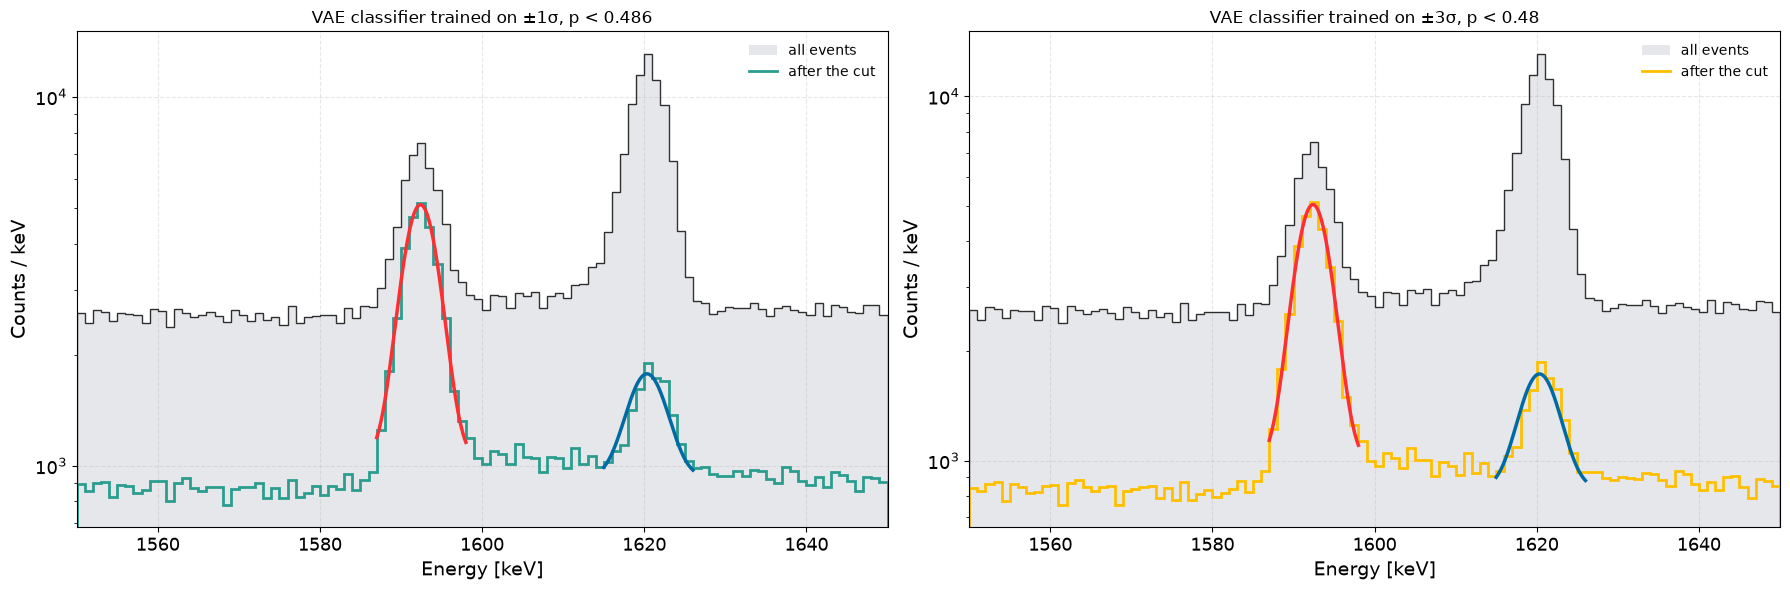

In [45]:
# check of the fits at the cuts: spectrum after the VAE cuts with the fixed-shape fit of DEP and FEP
fit_methods = {vae_name(s): METHODS[vae_name(s)] for s in VAE_SIGMAS}
fig, axes = plt.subplots(1, len(fit_methods), figsize=(9 * len(fit_methods), 6), squeeze=False)
h_tot, _ = np.histogram(energy, bins=FIT_BINS)
for ax, (name, m) in zip(axes.flat, fit_methods.items()):
    h_cut, _ = np.histogram(energy[m['kept']], bins=FIT_BINS)
    ax.stairs(h_tot, FIT_BINS, fill=True, color=pf.color1, alpha=0.3, label='all events')
    ax.stairs(h_tot, FIT_BINS, color='black', alpha=0.8, lw=1)
    ax.stairs(h_cut, FIT_BINS, color=m['color'], lw=2, label='after the cut')
    for peak, color in (('sse', pf.SSE_COLOR), ('mse', pf.MSE_COLOR)):
        bidx, X = DESIGN[peak]
        a, _, b = fixed_shape_fit(h_cut[bidx][None, :].astype(float), X)
        xx = np.linspace(*fit[peak]['window'], 200)
        ax.plot(xx, a[0] * norm.pdf(xx, fit[peak]['mu'], fit[peak]['sigma']) + b[0], color=color, lw=2.5)
    ax.set_xlim(E_MIN, E_MAX)
    ax.set_yscale('log')
    pf._style(ax, f"{name}, {m['cut_label']}", 'Energy [keV]', 'Counts / keV')
pf._finish(fig, os.path.join(LEAN_DIR, 'fits_at_the_cuts.pdf'))

# 4. CLASSIFICATION
Output of the classifiers on the training and test sets, true SSE (DEP window) and true MSE (FEP window).

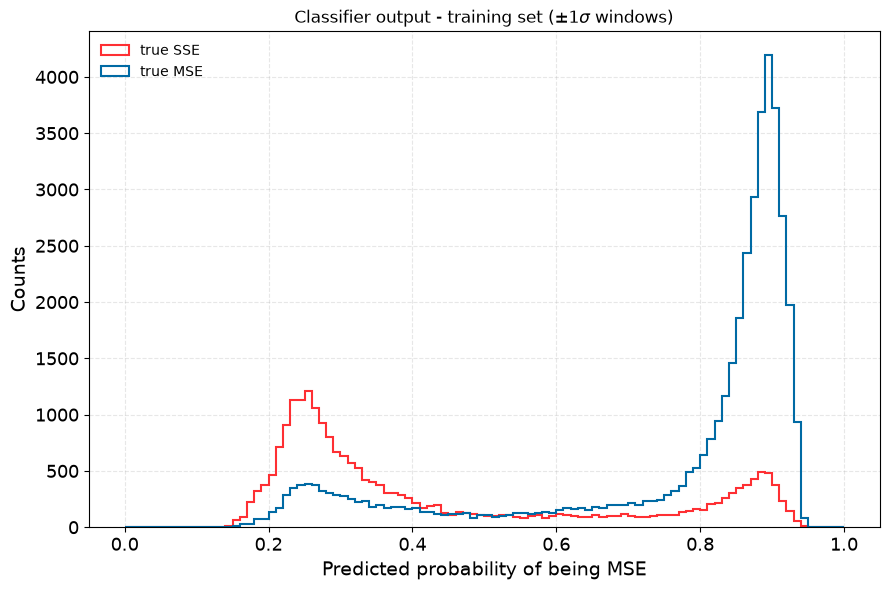

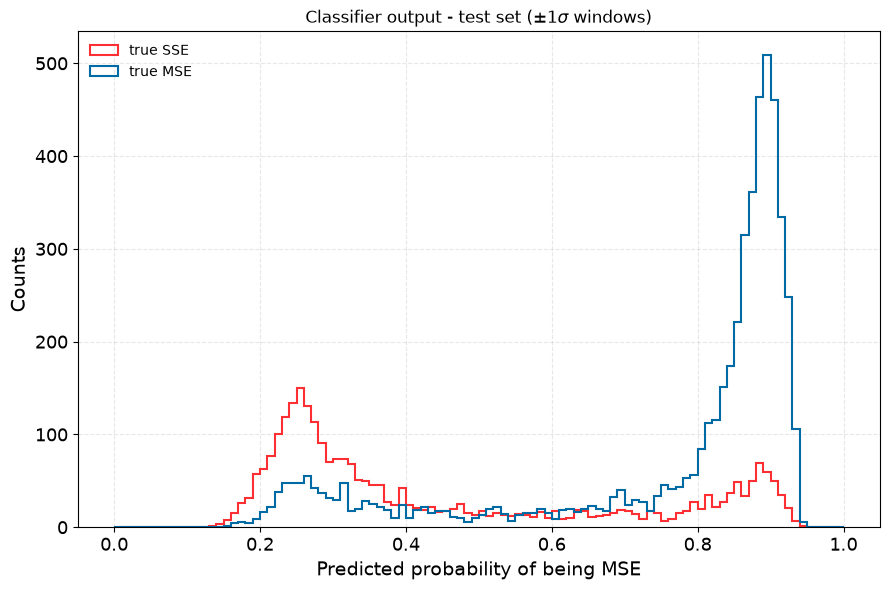

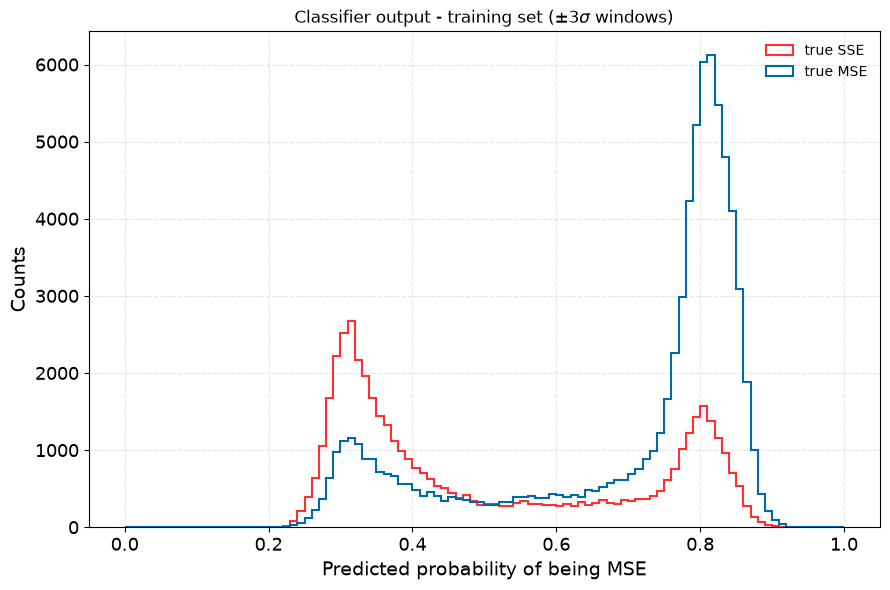

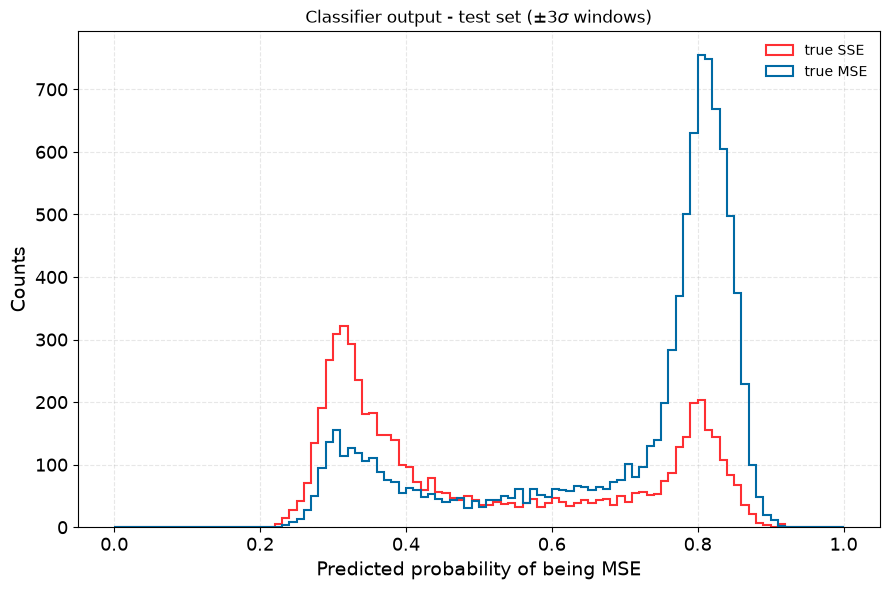

In [46]:
def plot_classifier_output(p, y, title, path):
    """Distribution of the predicted probability of being MSE, for true SSE and true MSE."""
    bins = np.linspace(0, 1, 101)
    fig, axes = pf.make_figure(1)
    ax = axes[0, 0]
    ax.hist(p[y == 0], bins=bins, histtype='step', lw=1.5, color=pf.SSE_COLOR, label='true SSE')
    ax.hist(p[y == 1], bins=bins, histtype='step', lw=1.5, color=pf.MSE_COLOR, label='true MSE')
    pf._style(ax, title, 'Predicted probability of being MSE', 'Counts')
    pf._finish(fig, path)


for s in VAE_SIGMAS:
    labels_all = np.full(len(energy), np.nan)
    labels_all[pred[s]['idx_labeled']] = pred[s]['y_labeled']
    for set_name, key in (('training set', 'idx_train'), ('test set', 'idx_test')):
        idx = pred[s][key]
        plot_classifier_output(p_vae[s][idx], labels_all[idx], f'Classifier output - {set_name} {pf.window_label(s)}',
                               os.path.join(LEAN_DIR, f"classifier_output_{set_name.split()[0]}_sigma{s:g}.pdf"))

# 5. ROC CURVES
### Net survival fractions (background subtracted)
One curve per method, valid for every window. Stars: the cuts at `DEP_TARGET`; empty circle: official A/E cut; black line: `DEP_TARGET`. The curves are smoothed over `SMOOTH` thresholds only for the plot (the fit fluctuates a little from one threshold to the next); stars, tables and AUC come from the fits without smoothing.
Right: zoom on the grey box. The stars are all at the same DEP SF by construction: in the zoom they are shifted a little sideways, otherwise they hide each other.

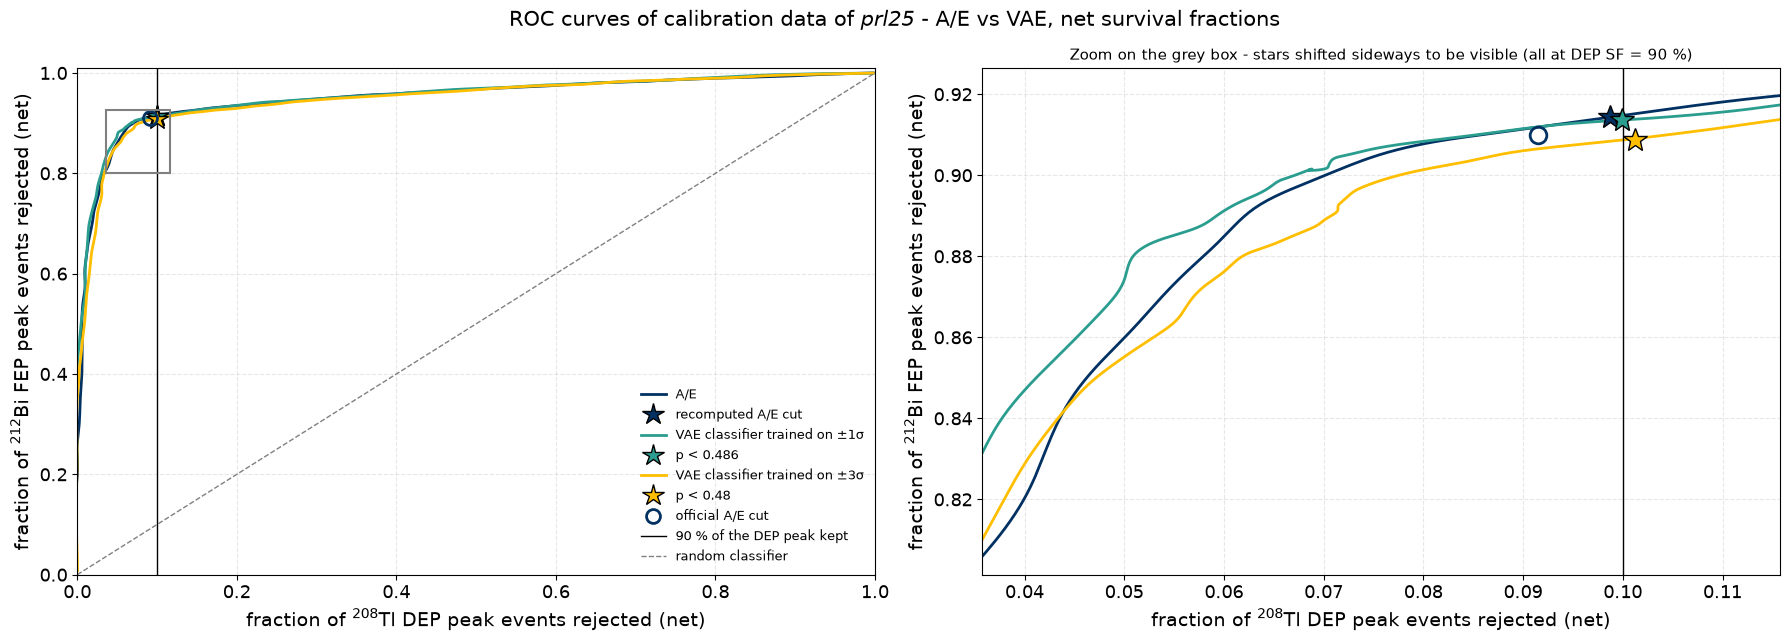

net FEP SF [%] at each net DEP SF:


,A/E,VAE classifier trained on ±1σ,VAE classifier trained on ±3σ
net DEP SF [%],,,
80,6.47,6.49,7.05
81,6.68,6.66,7.18
82,6.81,6.88,7.31
83,6.94,7.03,7.45
84,7.15,7.17,7.68
85,7.42,7.41,7.81
86,7.54,7.68,7.96
87,7.74,7.96,8.25
88,7.95,8.15,8.45



AUC of the net ROC curves:


A/E                              0.952
VAE classifier trained on ±1σ    0.955
VAE classifier trained on ±3σ    0.949
Name: AUC (net), dtype: float64

In [47]:
def zoom_limits(points, yerr=0.0, min_hx=0.02, min_hy=0.015):
    """x / y limits of the zoom: around the points, wide enough for their spread and for 3 x the error bars."""
    pts = np.asarray(points, dtype=float)
    (x0, y0), (x1, y1) = pts.min(axis=0), pts.max(axis=0)
    hx = max(min_hx, 0.75 * (x1 - x0) + 0.01)
    hy = max(min_hy, 0.75 * (y1 - y0) + 3 * yerr)
    return ((x0 + x1) / 2 - hx, (x0 + x1) / 2 + hx), ((y0 + y1) / 2 - hy, (y0 + y1) / 2 + hy)


def style_roc(a, xlabel, ylabel, xlim=(0, 1), ylim=(0, 1.01)):
    a.set_xlim(*xlim)
    a.set_ylim(*ylim)
    a.set_xlabel(xlabel)
    a.set_ylabel(ylabel)
    a.grid(alpha=0.3, ls='--')
    a.set_axisbelow(True)


def mark_zoom(ax, xlim, ylim):
    """Grey box on the full ROC: the region shown in the zoom panel."""
    ax.add_patch(Rectangle((xlim[0], ylim[0]), xlim[1] - xlim[0], ylim[1] - ylim[0],
                           fill=False, ec='grey', lw=1.5, zorder=6))


NET_X = r"fraction of ${}^{208}$Tl DEP peak events rejected (net)"
NET_Y = r"fraction of ${}^{212}$Bi FEP peak events rejected (net)"
DODGE = 0.0012          # zoom only: stars shifted sideways, otherwise they hide each other (all at the same DEP SF)

fig, (ax, az) = plt.subplots(1, 2, figsize=(18, 6.5))

WP_LABEL = f"{100*DEP_TARGET:.0f} % of the DEP peak kept"

# ---------------- left: full ROC ----------------
for name, m in METHODS.items():
    ax.plot(m['x_plot'], m['y_plot'], color=m['color'], lw=2, label=name)
    ax.plot(1 - m['dep'][0], 1 - m['fep'][0], marker='*', ms=16, color=m['color'], mec='black', ls='none', zorder=5,
            label=m['cut_label'])
ax.plot(1 - OFFICIAL['dep'][0], 1 - OFFICIAL['fep'][0], marker='o', ms=10, mfc='none', mec=pf.color2, mew=2, ls='none',
        zorder=5, label='official A/E cut')
ax.axvline(1 - DEP_TARGET, ls='-', color='black', lw=1, label=WP_LABEL)
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='random classifier')
style_roc(ax, NET_X, NET_Y)
ax.legend(frameon=False, loc='lower right', fontsize=9)

# ---------------- right: zoom on the cuts ----------------
n = len(METHODS)
for i, (name, m) in enumerate(METHODS.items()):
    az.plot(m['x_plot'], m['y_plot'], color=m['color'], lw=2)
    az.plot(1 - m['dep'][0] + (i - (n - 1) / 2) * DODGE, 1 - m['fep'][0], marker='*', ms=18,
            color=m['color'], mec='black', ls='none', zorder=5)
az.plot(1 - OFFICIAL['dep'][0], 1 - OFFICIAL['fep'][0], marker='o', ms=12, mfc='none', mec=pf.color2, mew=2, ls='none', zorder=5)
az.axvline(1 - DEP_TARGET, ls='-', color='black', lw=1)
points = [(1 - m['dep'][0], 1 - m['fep'][0]) for m in METHODS.values()] + [(1 - OFFICIAL['dep'][0], 1 - OFFICIAL['fep'][0])]
ZOOM_LEFT = 0.04          # how much wider the zoom goes towards the left
xlim, ylim = zoom_limits(points)
xlim = (xlim[0] - ZOOM_LEFT, xlim[1])
y_low = min(m['y_plot'][(m['x_plot'] >= xlim[0]) & (m['x_plot'] <= xlim[1])].min() for m in METHODS.values())
ylim = (min(ylim[0], y_low - 0.005), ylim[1])
style_roc(az, NET_X, NET_Y, xlim, ylim)
az.set_title(f"Zoom on the grey box - stars shifted sideways to be visible (all at DEP SF = {100*DEP_TARGET:.0f} %)",
             fontsize=11)
mark_zoom(ax, xlim, ylim)

fig.suptitle(r"ROC curves of calibration data of $\mathit{prl25}$ - A/E vs VAE, net survival fractions", fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(LEAN_DIR, 'roc_net.pdf'), dpi=300)
plt.show()

# net FEP SF [%] of every method (columns) at several net DEP SF (rows)
net_table = pd.DataFrame(
    {name: [100 * net_sf_of_mask(m['score'] < threshold_at(m['thr'], m['sf_dep'], target))[1][0] for target in TARGETS]
     for name, m in METHODS.items()},
    index=pd.Index([f'{100*t:.0f}' for t in TARGETS], name='net DEP SF [%]'))
net_table.to_csv(os.path.join(LEAN_DIR, 'roc_net.csv'))
print('net FEP SF [%] at each net DEP SF:')
display(net_table.round(2))
print('\nAUC of the net ROC curves:')
display(pd.Series({name: m['auc_net'] for name, m in METHODS.items()}, name='AUC (net)').round(3))

In [48]:
# LaTeX table: net FEP SF (± statistical error) at every net DEP SF; lowest value of each row in bold
header = {'A/E': r'\ac{AE}', **{vae_name(s): rf'\ac{{VAE}} $\pm{s:g}\sigma$' for s in VAE_SIGMAS}}
lines = [r'\begin{table}[H]', r'    \centering',
         r'    \begin{tabular}{c' + 'c' * len(METHODS) + '}', r'        \toprule',
         r'        Net \ac{DEP} SF [\%] & ' + ' & '.join(header[n] for n in METHODS) + r' \\', r'        \midrule']
for target in TARGETS:
    vals = {n: net_sf_of_mask(m['score'] < threshold_at(m['thr'], m['sf_dep'], target))[1] for n, m in METHODS.items()}
    best = min(vals, key=lambda n: vals[n][0])
    cells = [(r'\textbf{%.2f} $\pm$ %.2f' if n == best else r'%.2f $\pm$ %.2f') % (100 * v[0], 100 * v[1])
             for n, v in vals.items()]
    lines.append(f'        {100*target:.0f} & ' + ' & '.join(cells) + r' \\')
lines += [r'        \bottomrule', r'    \end{tabular}',
          r'    \caption{Net survival fraction of the \ac{FEP} peak, in \%, for the cuts that keep a given net survival '
          r'fraction of the \ac{DEP} peak. The uncertainties are statistical (Eq.~\ref{eq:sf-error}); '
          r'the lowest value of each row, i.e.\ the best rejection of \ac{MSE}, is in bold.}',
          r'    \label{tab:net-scan}', r'\end{table}']
print('\n'.join(lines))

\begin{table}[H]
    \centering
    \begin{tabular}{cccc}
        \toprule
        Net \ac{DEP} SF [\%] & \ac{AE} & \ac{VAE} $\pm1\sigma$ & \ac{VAE} $\pm3\sigma$ \\
        \midrule
        80 & \textbf{6.47} $\pm$ 0.31 & 6.49 $\pm$ 0.31 & 7.05 $\pm$ 0.31 \\
        81 & 6.68 $\pm$ 0.31 & \textbf{6.66} $\pm$ 0.32 & 7.18 $\pm$ 0.32 \\
        82 & \textbf{6.81} $\pm$ 0.32 & 6.88 $\pm$ 0.32 & 7.31 $\pm$ 0.32 \\
        83 & \textbf{6.94} $\pm$ 0.32 & 7.03 $\pm$ 0.32 & 7.45 $\pm$ 0.32 \\
        84 & \textbf{7.15} $\pm$ 0.33 & 7.17 $\pm$ 0.33 & 7.68 $\pm$ 0.33 \\
        85 & 7.42 $\pm$ 0.33 & \textbf{7.41} $\pm$ 0.33 & 7.81 $\pm$ 0.33 \\
        86 & \textbf{7.54} $\pm$ 0.33 & 7.68 $\pm$ 0.34 & 7.96 $\pm$ 0.34 \\
        87 & \textbf{7.74} $\pm$ 0.34 & 7.96 $\pm$ 0.34 & 8.25 $\pm$ 0.34 \\
        88 & \textbf{7.95} $\pm$ 0.34 & 8.15 $\pm$ 0.35 & 8.45 $\pm$ 0.34 \\
        89 & \textbf{8.19} $\pm$ 0.35 & 8.46 $\pm$ 0.36 & 8.85 $\pm$ 0.35 \\
        90 & \textbf{8.57} $\pm$ 0.35 & 8.64 $\p

### ±$k\sigma$ windows
Labels: DEP (0) and FEP (1) in the ±$k\sigma$ windows, counts **including the background**. Stars: the same cuts at `DEP_TARGET` net; empty circle: official A/E cut. Right: zoom on the grey box.
All the labelled events are used (training events of the classifiers included). AUC values in the table.
AUC errors: paired, stratified bootstrap.

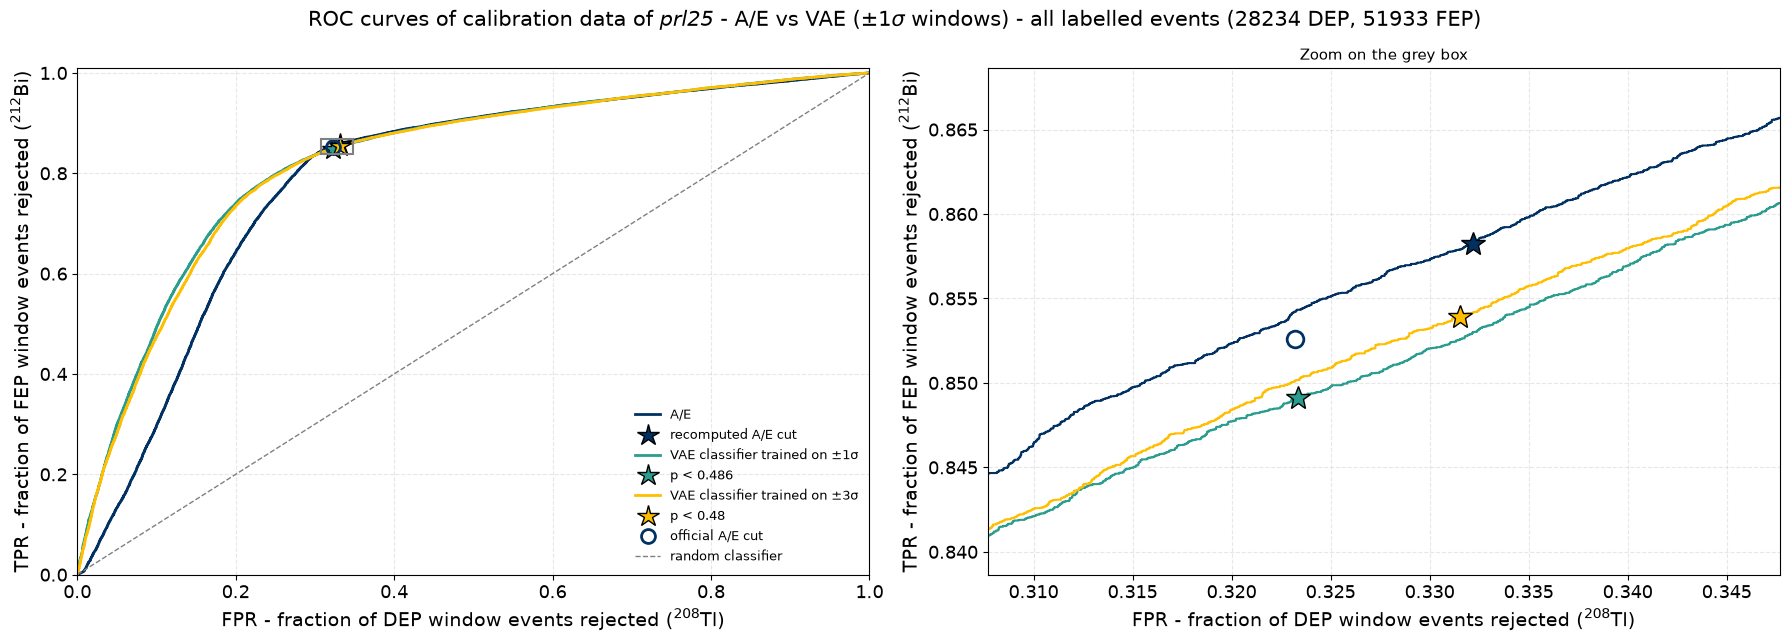

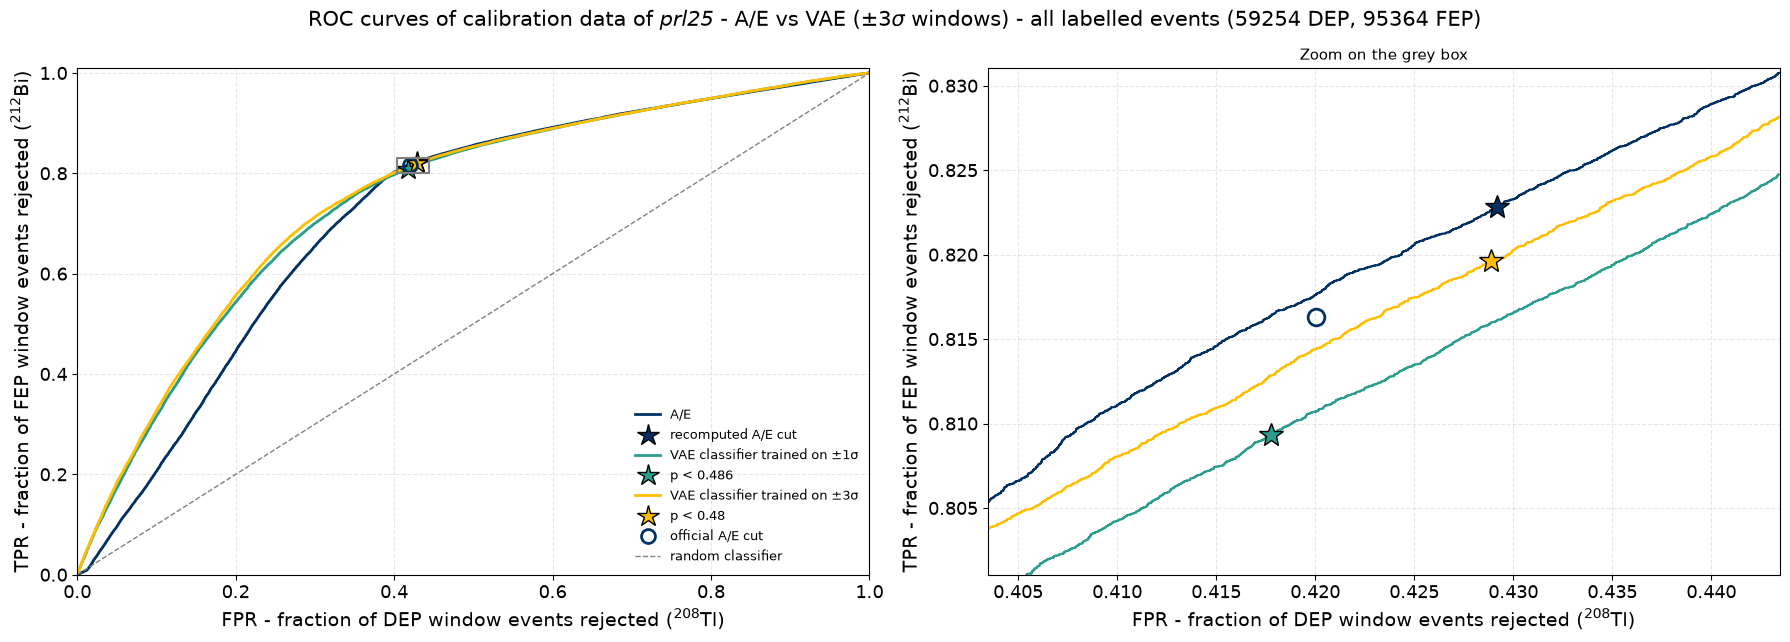

N DEP  N FEP  \
windows events              method                                        
±1σ     all labelled events A/E                            28234  51933   
                            VAE classifier trained on ±1σ  28234  51933   
                            VAE classifier trained on ±3σ  28234  51933   
±3σ     all labelled events A/E                            59254  95364   
                            VAE classifier trained on ±1σ  59254  95364   
                            VAE classifier trained on ±3σ  59254  95364   

                                                             AUC  AUC err  \
windows events              method                                          
±1σ     all labelled events A/E                            0.792    0.002   
                            VAE classifier trained on ±1σ  0.826    0.002   
                            VAE classifier trained on ±3σ  0.823    0.002   
±3σ     all labelled events A/E                            0.721    0.001   
                            VAE classifier trained on ±1σ  0.748    0.001   
                            VAE classifier trained on ±3σ  0.752    0.001   

                                                           DEP SF of the cut [%]  \
windows events              method                                                 
±1σ     all labelled events A/E                                           66.781   
                            VAE classifier trained on ±1σ                 67.663   
                            VAE classifier trained on ±3σ                 66.848   
±3σ     all labelled events A/E                                           57.083   
                            VAE classifier trained on ±1σ                 58.224   
                            VAE classifier trained on ±3σ                 57.112   

                                                           FEP SF of the cut [%]  \
windows events              method                                                 
±1σ     all labelled events A/E                                           14.180   
                            VAE classifier trained on ±1σ                 15.091   
                            VAE classifier trained on ±3σ                 14.607   
±3σ     all labelled events A/E                                           17.721   
                            VAE classifier trained on ±1σ                 19.069   
                            VAE classifier trained on ±3σ                 18.039   

                                                           FEP SF @ 90 % DEP window SF [%]  \
windows events              method                                                           
±1σ     all labelled events A/E                                                     70.344   
                            VAE classifier trained on ±1σ                           50.665   
                            VAE classifier trained on ±3σ                           52.525   
±3σ     all labelled events A/E                                                     79.375   
                            VAE classifier trained on ±1σ                           68.372   
                            VAE classifier trained on ±3σ                           67.341   

                                                           FEP SF @ DEP SF of the official A/E cut [%]  
windows events              method                                                                      
±1σ     all labelled events A/E                                                                 14.578  
                            VAE classifier trained on ±1σ                                       15.093  
                            VAE classifier trained on ±3σ                                       14.985  
±3σ     all labelled events A/E                                                                 18.237  
                            VAE classifier trained on ±1σ                                       18.929  
       

In [49]:
roc_rows = []
for k in VAE_SIGMAS:
    in_dep, in_fep = prel.window_mask(energy, fit['sse'], k), prel.window_mask(energy, fit['mse'], k)
    labelled = in_dep | in_fep

    for events, ftag, sel in (('all labelled events', 'all', labelled),):
        y = in_fep[sel].astype(int)            # 0 = DEP, 1 = FEP
        # NaN score (e.g. A/E not available) -> treated as the most MSE-like value
        scores = {name: np.nan_to_num(m['score'][sel], nan=np.nanmax(m['score']) + 1) for name, m in METHODS.items()}
        auc = prel.bootstrap_auc(y, scores, n_boot=N_BOOT, seed=SEED)
        fpr_official = prel.operating_point(~a_ok[sel], y)[0]

        WIN_X = r"FPR - fraction of DEP window events rejected (${}^{208}$Tl)"
        WIN_Y = r"TPR - fraction of FEP window events rejected (${}^{212}$Bi)"
        fig, (ax, az) = plt.subplots(1, 2, figsize=(18, 6.5))
        off = prel.operating_point(~a_ok[sel], y)
        stars = {}
        for name, m in METHODS.items():
            fpr, tpr, _ = roc_curve(y, scores[name])
            stars[name] = prel.operating_point(~m['kept'][sel], y)
            for a in (ax, az):
                a.plot(fpr, tpr, color=m['color'], lw=2 if a is ax else 1.5, label=name if a is ax else None)
                a.plot(*stars[name], marker='*', ms=16 if a is ax else 18, color=m['color'], mec='black', ls='none', zorder=5,
                       label=m['cut_label'] if a is ax else None)
            roc_rows.append({'windows': f'±{k:g}σ', 'events': events, 'method': name,
                             'N DEP': int((y == 0).sum()), 'N FEP': int((y == 1).sum()),
                             'AUC': auc[name]['auc'], 'AUC err': auc[name]['err'],
                             'DEP SF of the cut [%]': 100 * (1 - stars[name][0]), 'FEP SF of the cut [%]': 100 * (1 - stars[name][1]),
                             f'FEP SF @ {100*(1-FPR_REF):.0f} % DEP window SF [%]': 100 * (1 - np.interp(FPR_REF, fpr, tpr)),
                             'FEP SF @ DEP SF of the official A/E cut [%]': 100 * (1 - np.interp(fpr_official, fpr, tpr))})
        for a in (ax, az):
            a.plot(*off, marker='o', ms=10 if a is ax else 12, mfc='none', mec=pf.color2, mew=2, ls='none', zorder=5,
                   label='official A/E cut' if a is ax else None)
        ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='random classifier')
        style_roc(ax, WIN_X, WIN_Y)
        ax.legend(frameon=False, loc='lower right', fontsize=9)

        xlim, ylim = zoom_limits(list(stars.values()) + [off])
        style_roc(az, WIN_X, WIN_Y, xlim, ylim)
        az.set_title("Zoom on the grey box", fontsize=11)
        mark_zoom(ax, xlim, ylim)

        fig.suptitle(rf"ROC curves of calibration data of $\mathit{{prl25}}$ - A/E vs VAE ($\pm${k:g}$\sigma$ windows)"
                     f" - {events} ({(y == 0).sum()} DEP, {(y == 1).sum()} FEP)", fontsize=15)
        fig.tight_layout()
        fig.savefig(os.path.join(LEAN_DIR, f'roc_windows_sigma{k:g}_{ftag}.pdf'), dpi=300)
        plt.show()

roc_table = pd.DataFrame(roc_rows).set_index(['windows', 'events', 'method'])
roc_table.to_csv(os.path.join(LEAN_DIR, 'roc_windows.csv'))
display(roc_table.round(3))

# 6. CLUSTERING
### Latent space
Distribution of every latent mean for true SSE (DEP window) and true MSE (FEP window), on the test set; $\rho$ = Spearman correlation of each dimension with A/E and rise time (all the events).

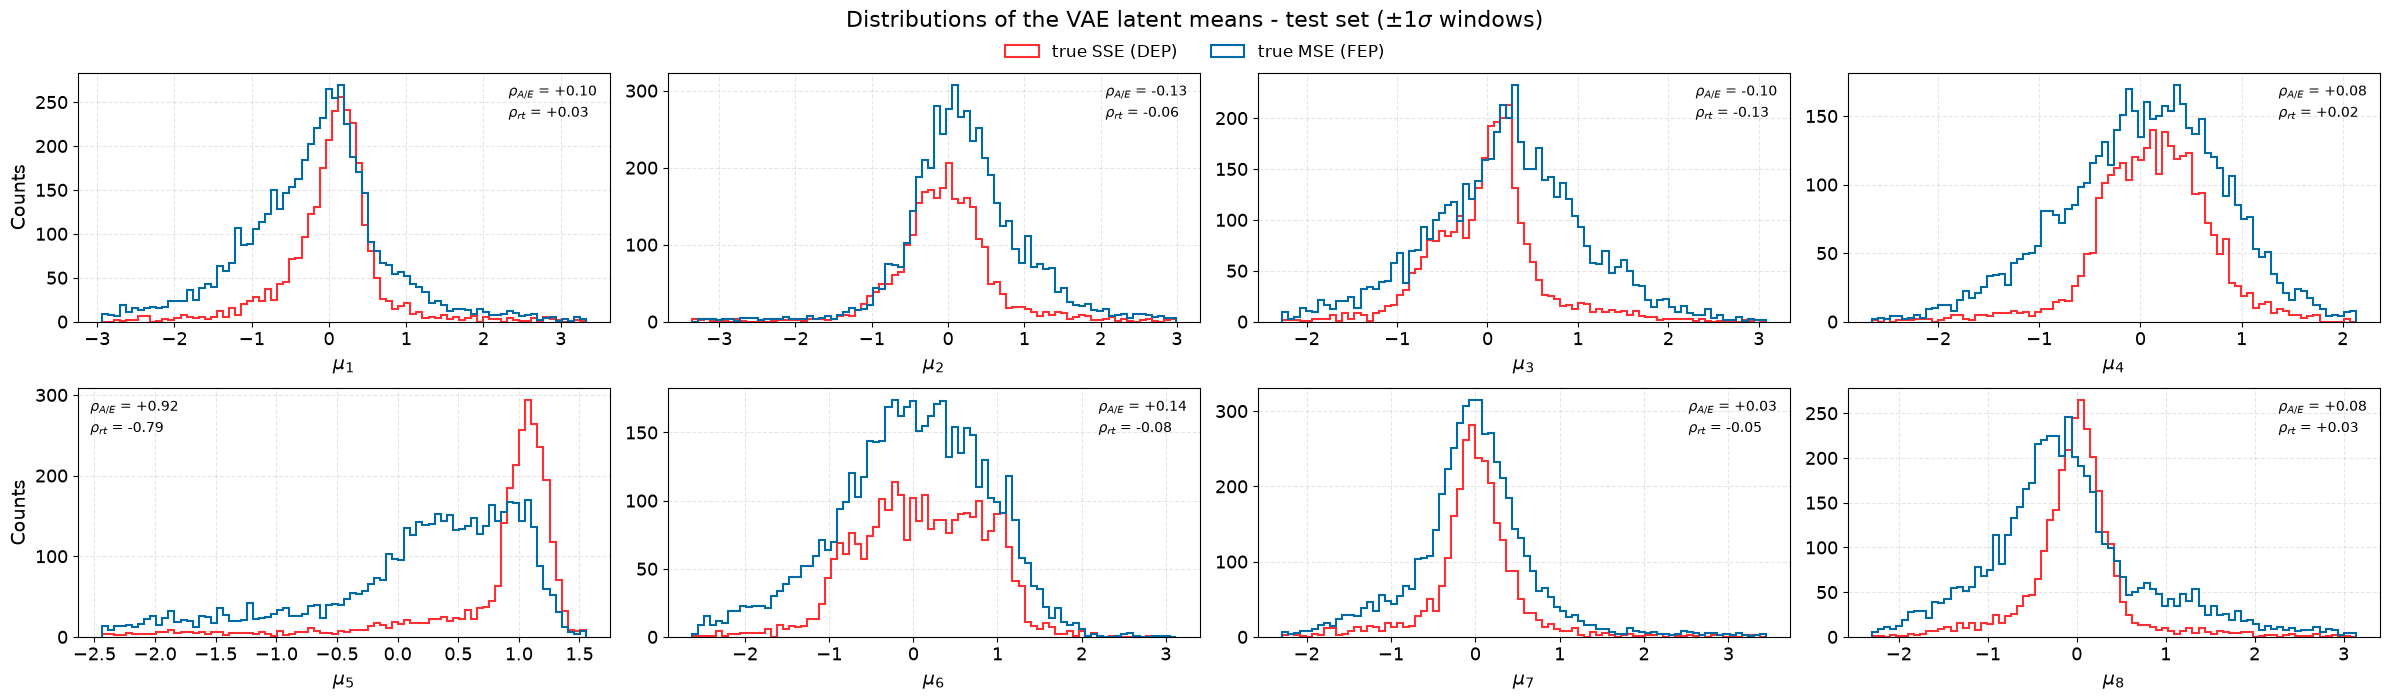

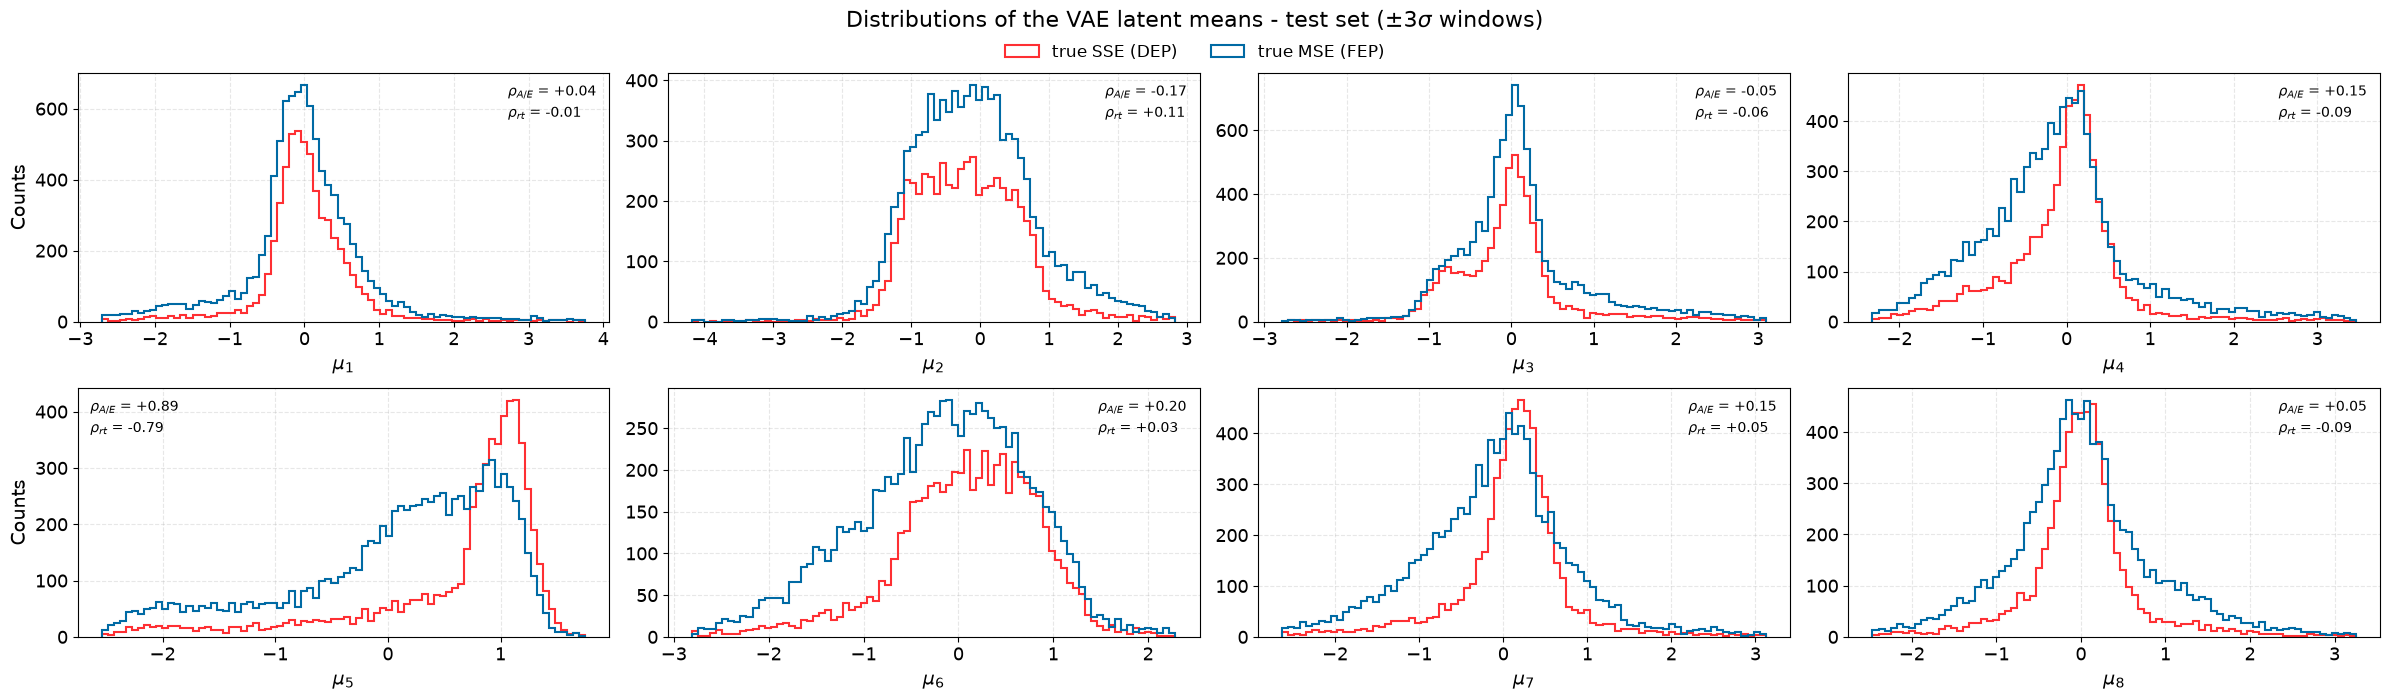

In [50]:
for s in VAE_SIGMAS:
    mu_all, idx_test = pred[s]['mu_all'], pred[s]['idx_test']
    labels_all = np.full(len(energy), np.nan)
    labels_all[pred[s]['idx_labeled']] = pred[s]['y_labeled']
    pf.plot_latent_distributions(mu_all[idx_test], labels_all[idx_test],
                                 rho_aoe=prel.latent_correlations(mu_all, aoe_val),
                                 rho_risetime=prel.latent_correlations(mu_all, rt_val),
                                 sigma=s, set_name='test set',
                                 path=os.path.join(LEAN_DIR, f'latent_distributions_test_sigma{s:g}.pdf'))

### A/E vs VAE, event by event: waveforms
Cuts at `DEP_TARGET` (A/E recomputed). One row per classifier. Processed current **not scaled**.

A/E keeps 114020 / 348999 events (32.7 %)

VAE trained on ±1σ (p < 0.486)
   kept by VAE          :  120536 ( 34.5 %)
   kept by both         :  107954 ( 30.9 %)
   rejected only by A/E :   12582 (  3.6 %)
   rejected only by VAE :    6066 (  1.7 %)
   rejected by both     :  222397 ( 63.7 %)
   agreement with A/E   :  94.7 %

VAE trained on ±3σ (p < 0.48)
   kept by VAE          :  115479 ( 33.1 %)
   kept by both         :  106307 ( 30.5 %)
   rejected only by A/E :    9172 (  2.6 %)
   rejected only by VAE :    7713 (  2.2 %)
   rejected by both     :  225807 ( 64.7 %)
   agreement with A/E   :  95.2 %



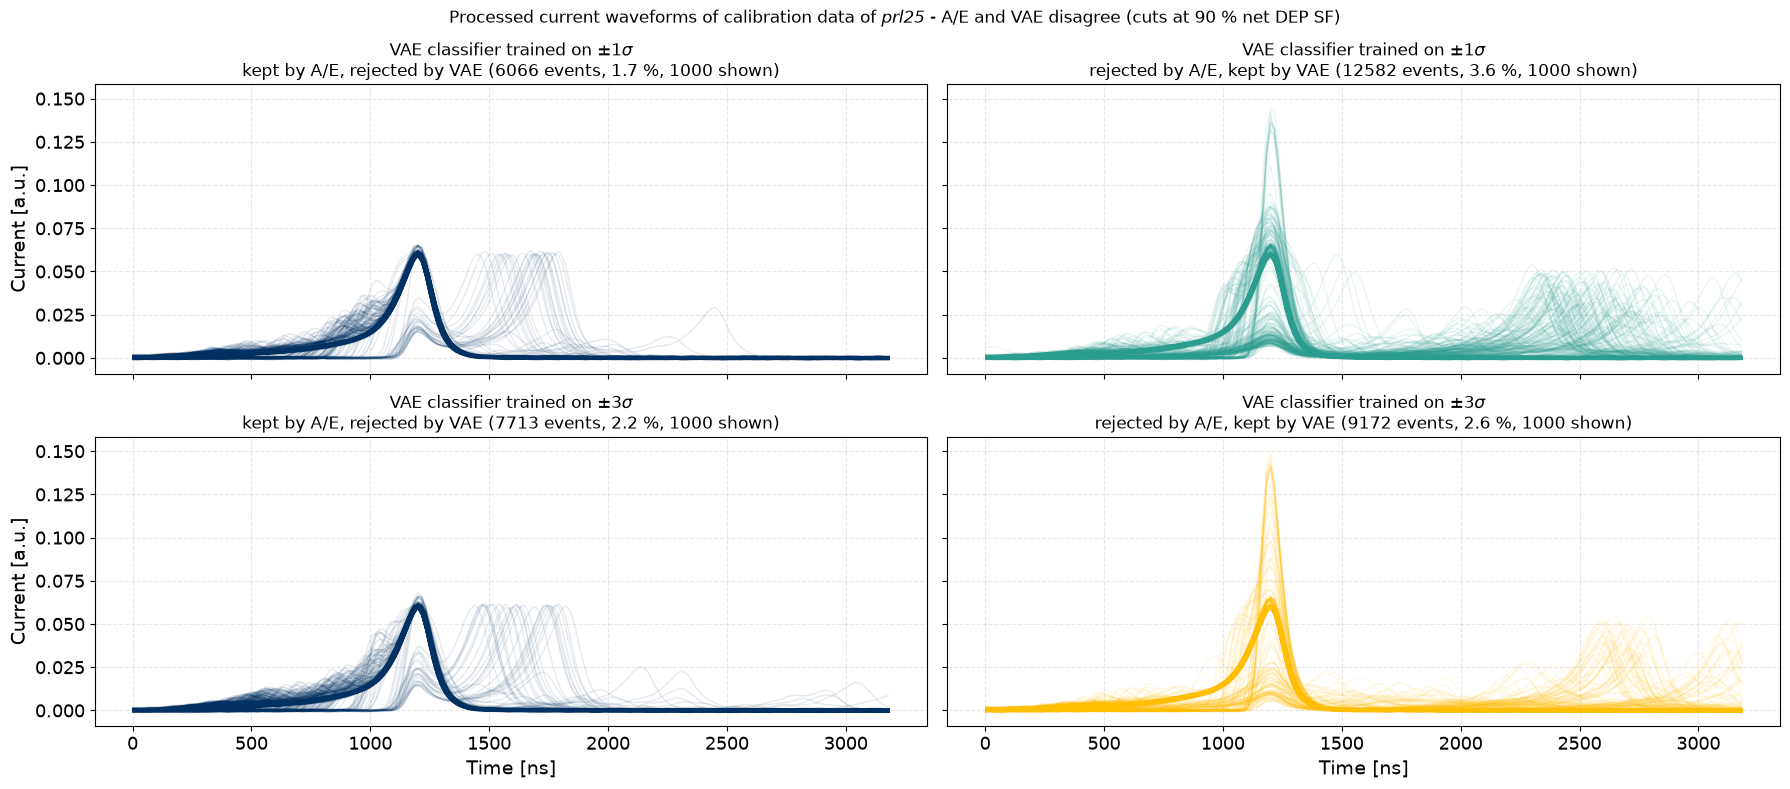

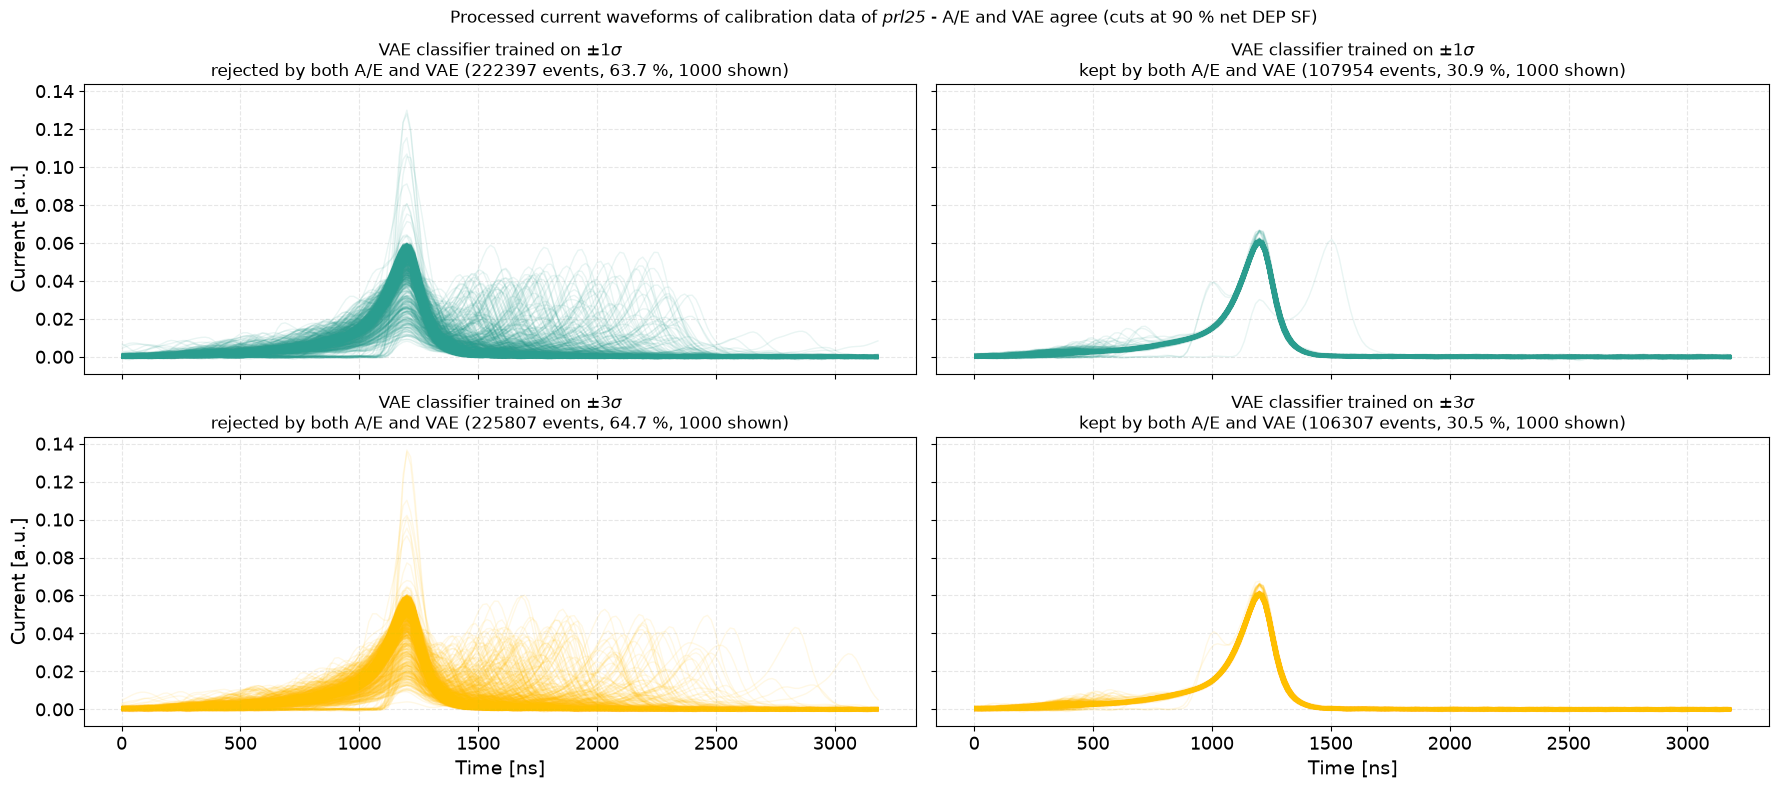

In [51]:
cur = clean['current']
t_ns = np.arange(cur.shape[1]) * pf.DT_NS
wp = f"(cuts at {100*DEP_TARGET:.0f} % net DEP SF)"

print(f"A/E keeps {a_cut.sum()} / {len(a_cut)} events ({a_cut.mean()*100:.1f} %)\n")
for s in VAE_SIGMAS:
    k = kept[s]
    print(f"VAE trained on ±{s:g}σ (p < {thr_vae[s]:.3g})")
    for lab, m in [("kept by VAE", k), ("kept by both", a_cut & k), ("rejected only by A/E", ~a_cut & k),
                   ("rejected only by VAE", a_cut & ~k), ("rejected by both", ~a_cut & ~k)]:
        print(f"   {lab:21s}: {m.sum():7d} ({m.mean()*100:5.1f} %)")
    print(f"   agreement with A/E   : {np.mean(a_cut == k)*100:5.1f} %\n")

disagree = lambda s, k: [(a_cut & ~k, pf.color2,    "kept by A/E, rejected by VAE"),
                         (~a_cut & k, vae_color(s), "rejected by A/E, kept by VAE")]
agree    = lambda s, k: [(~a_cut & ~k, vae_color(s), "rejected by both A/E and VAE"),
                         (a_cut & k,   vae_color(s), "kept by both A/E and VAE")]


def plot_wf_grid(panels_of, suptitle, savepath, n_show=N_SHOW, seed=0):
    fig, axes = plt.subplots(len(VAE_SIGMAS), 2, figsize=(18, 4 * len(VAE_SIGMAS)), sharex=True, sharey=True, squeeze=False)
    rng = np.random.default_rng(seed)
    for row, s in enumerate(VAE_SIGMAS):
        for col, (mask, color, lab) in enumerate(panels_of(s, kept[s])):
            ax, idx = axes[row, col], np.flatnonzero(mask)
            n_shown = min(n_show, len(idx))
            if n_shown == 0:
                ax.text(0.5, 0.5, "no events", ha='center', va='center', transform=ax.transAxes)
            else:
                sel = rng.choice(idx, size=n_shown, replace=False)
                segs = np.stack([np.broadcast_to(t_ns, (n_shown, len(t_ns))), cur[sel]], axis=-1)
                ax.add_collection(LineCollection(segs, colors=color, linewidths=1, alpha=0.1))
                ax.autoscale_view()
            ax.set_title(f"{vae_title(s)}\n{lab} ({len(idx)} events, {len(idx)/len(mask)*100:.1f} %, {n_shown} shown)")
            ax.grid(alpha=0.3, ls='--')
            ax.set_axisbelow(True)
        axes[row, 0].set_ylabel("Current [a.u.]")
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(suptitle)
    fig.tight_layout()
    fig.savefig(savepath, dpi=300)
    plt.show()


for panels_of, what in ((disagree, 'disagree'), (agree, 'agree')):
    plot_wf_grid(panels_of, rf"Processed current waveforms of calibration data of $\mathit{{prl25}}$ - A/E and VAE {what} {wp}",
                 os.path.join(LEAN_DIR, f'waveforms_{what}.pdf'))

### A/E vs VAE, event by event: energy, A/E and rise time
Same categories and colours; all the events, no sampling. A/E and rise time on the 0.1-99.9 % quantiles of all the events.

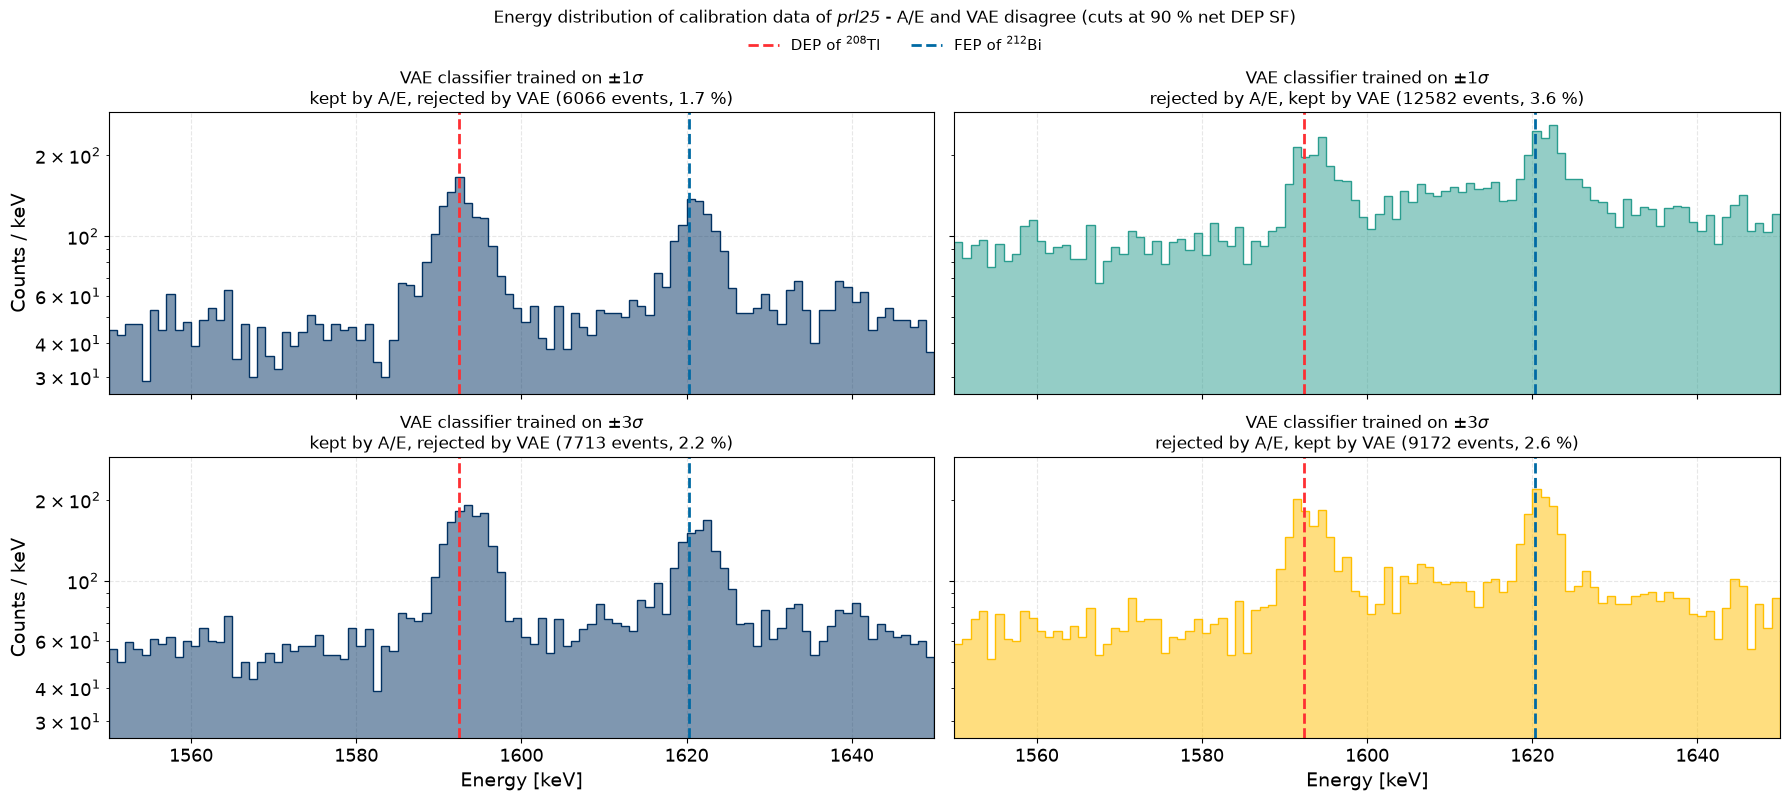

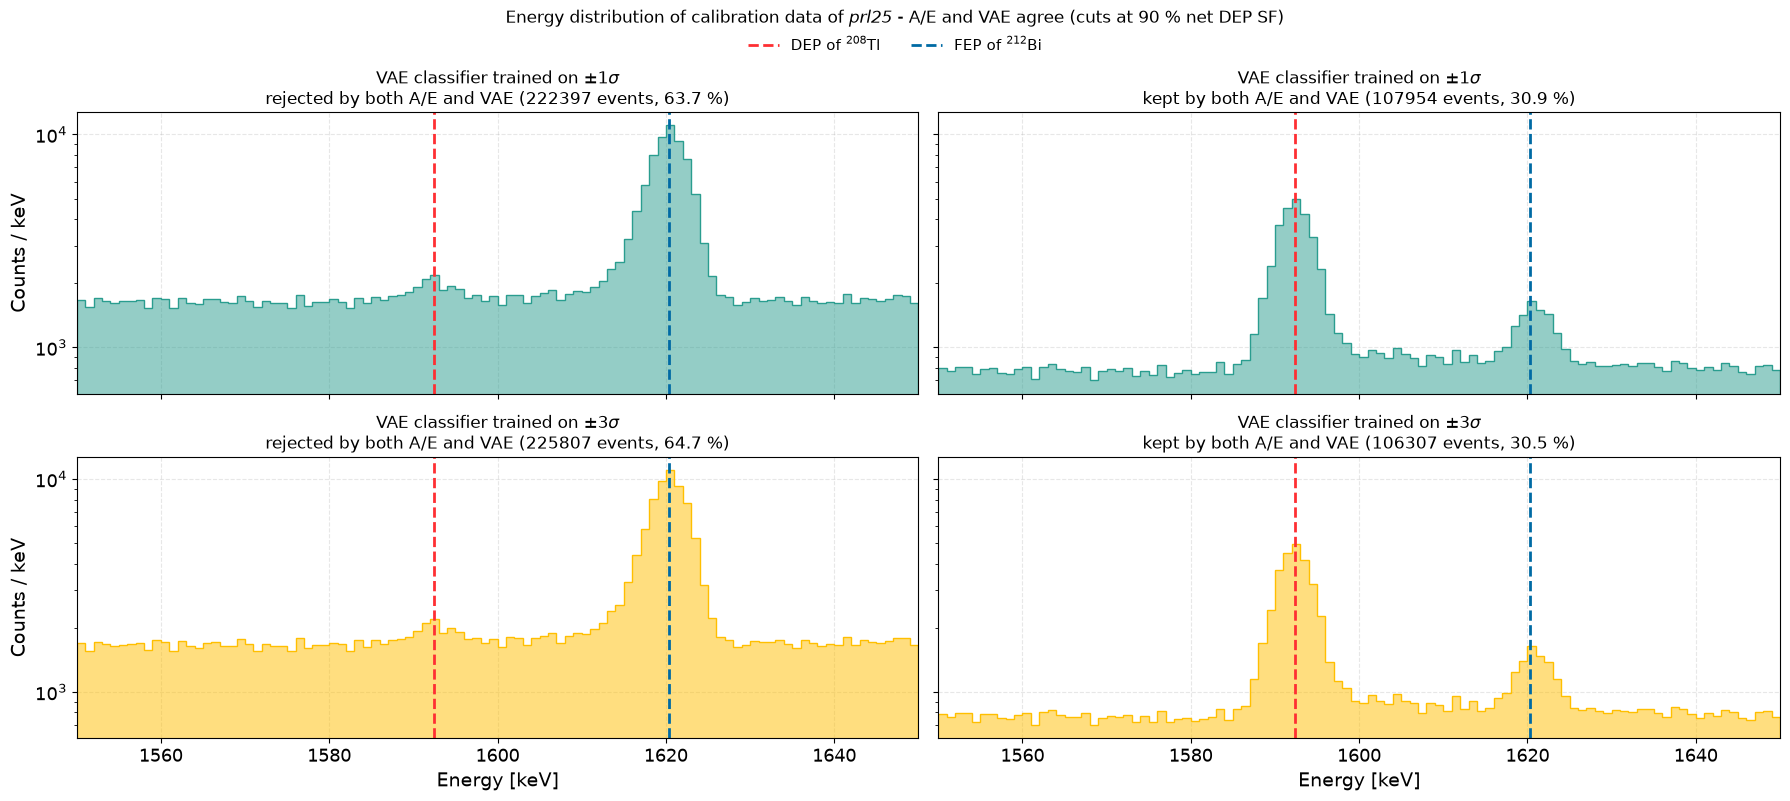

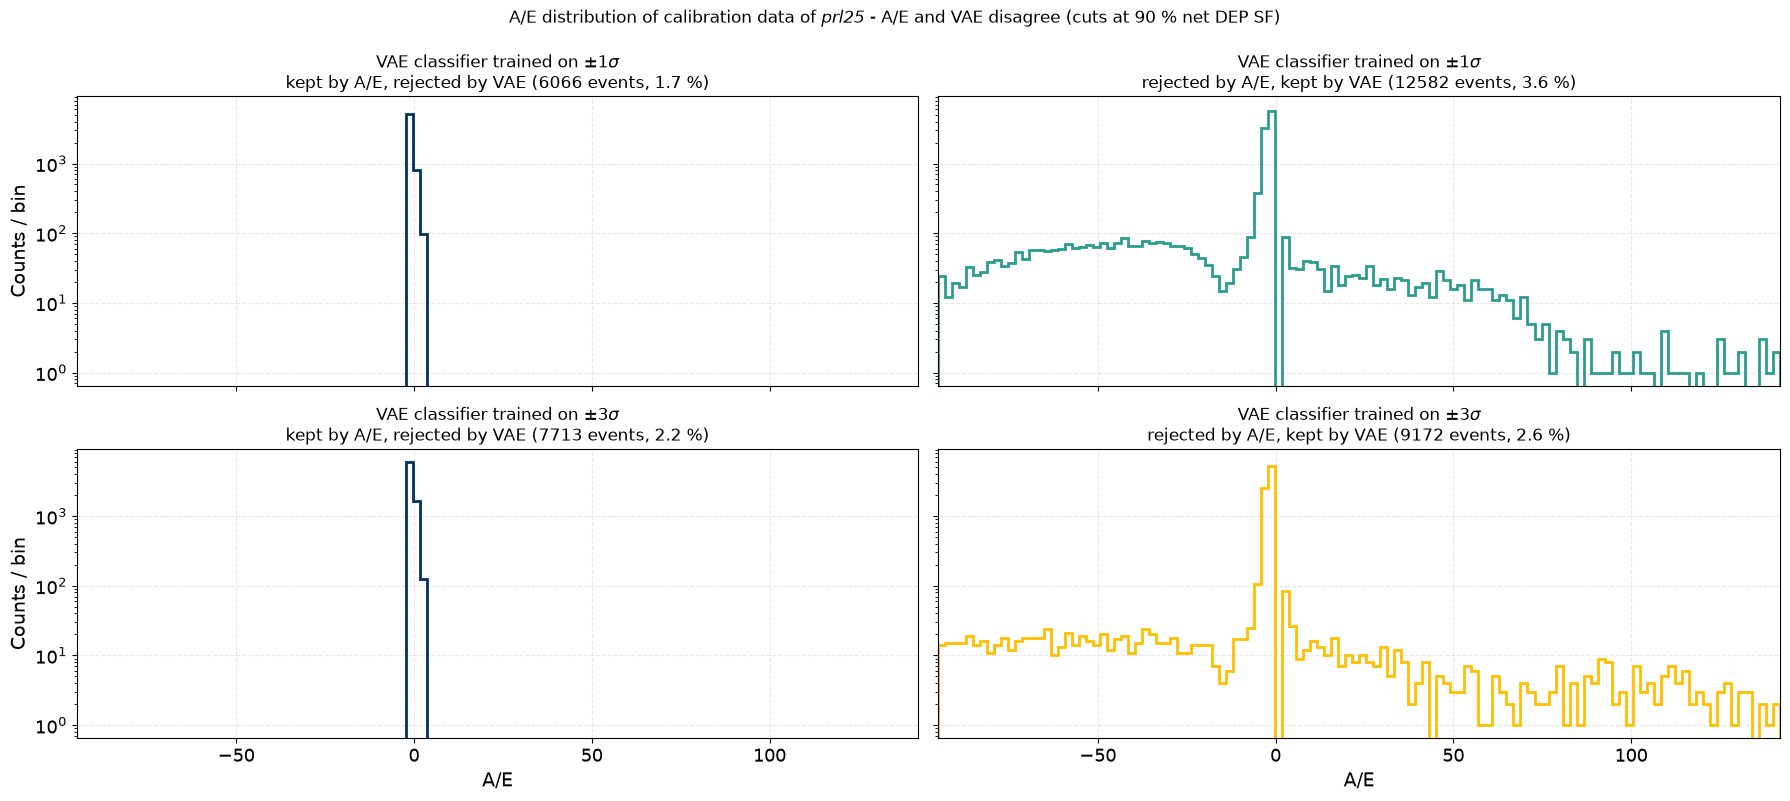

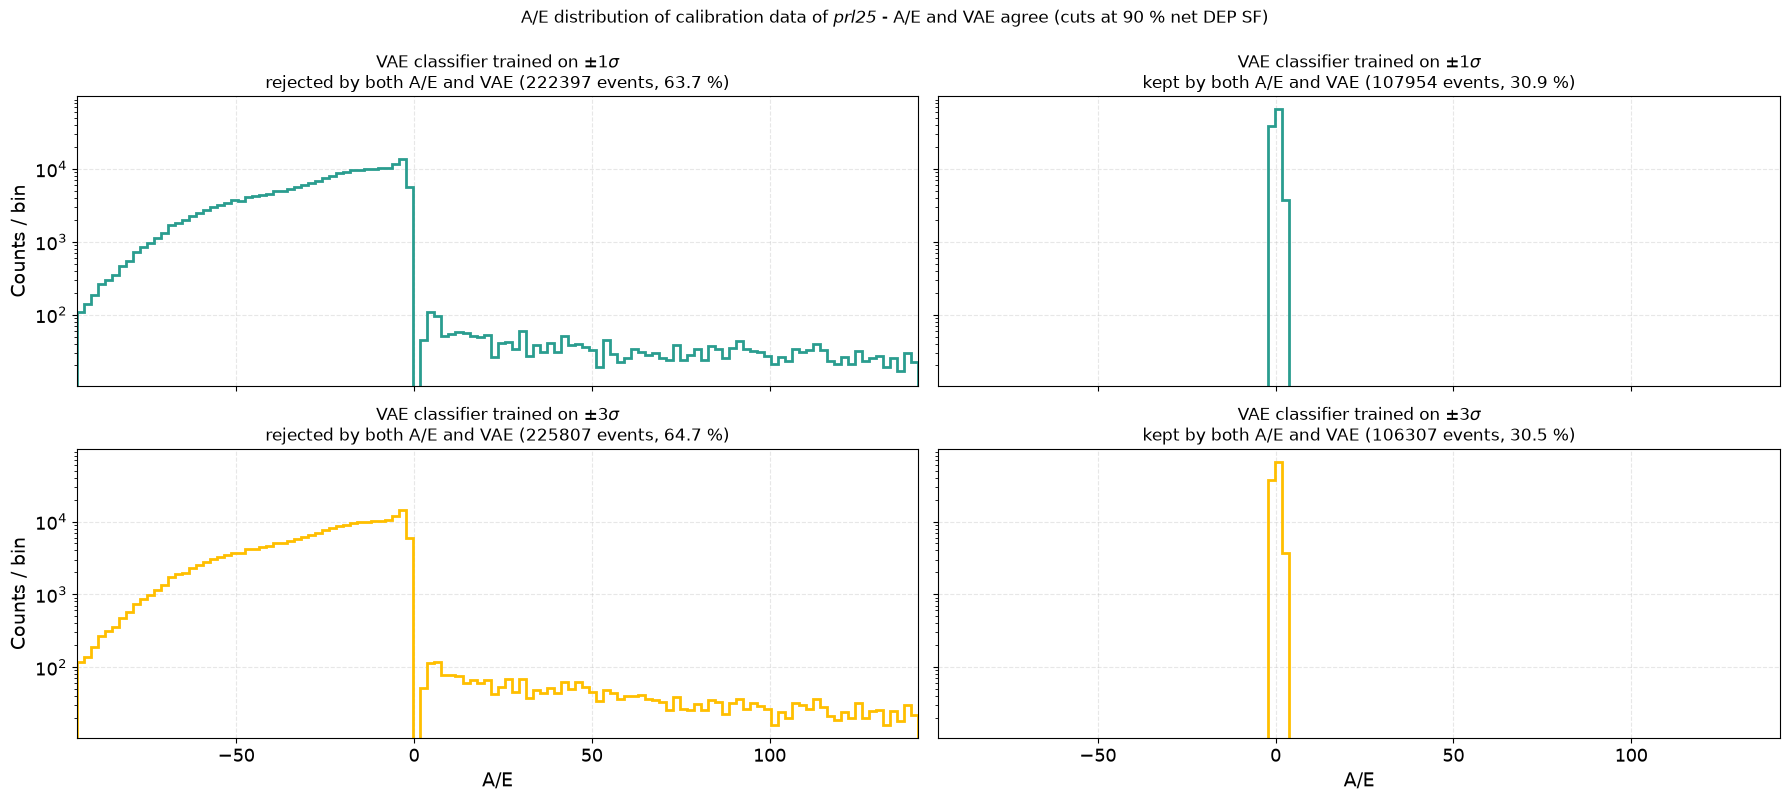

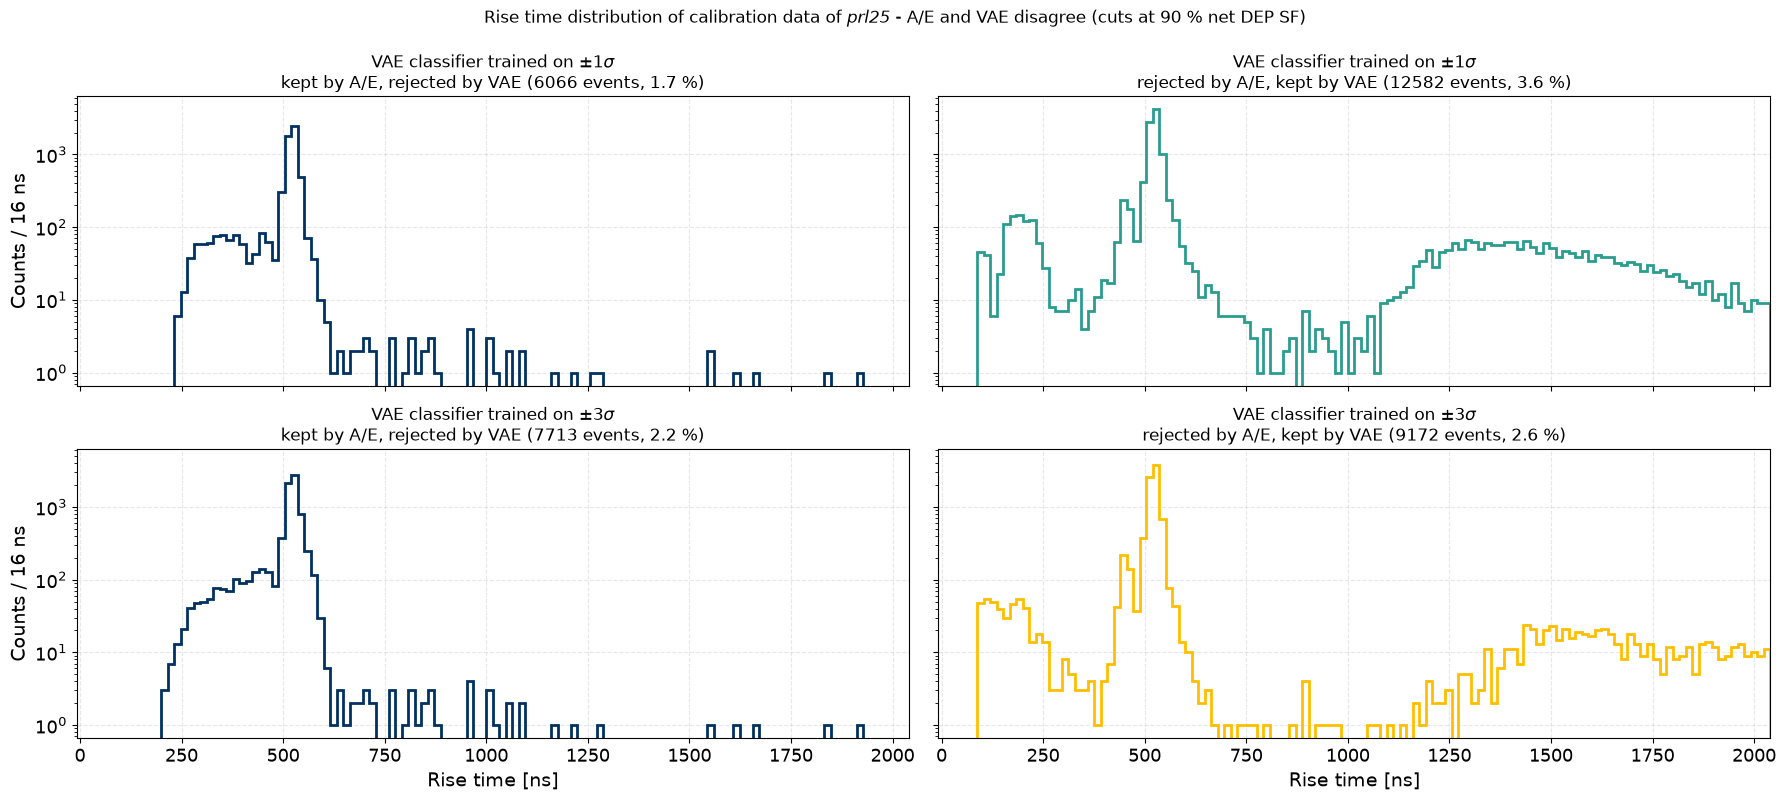

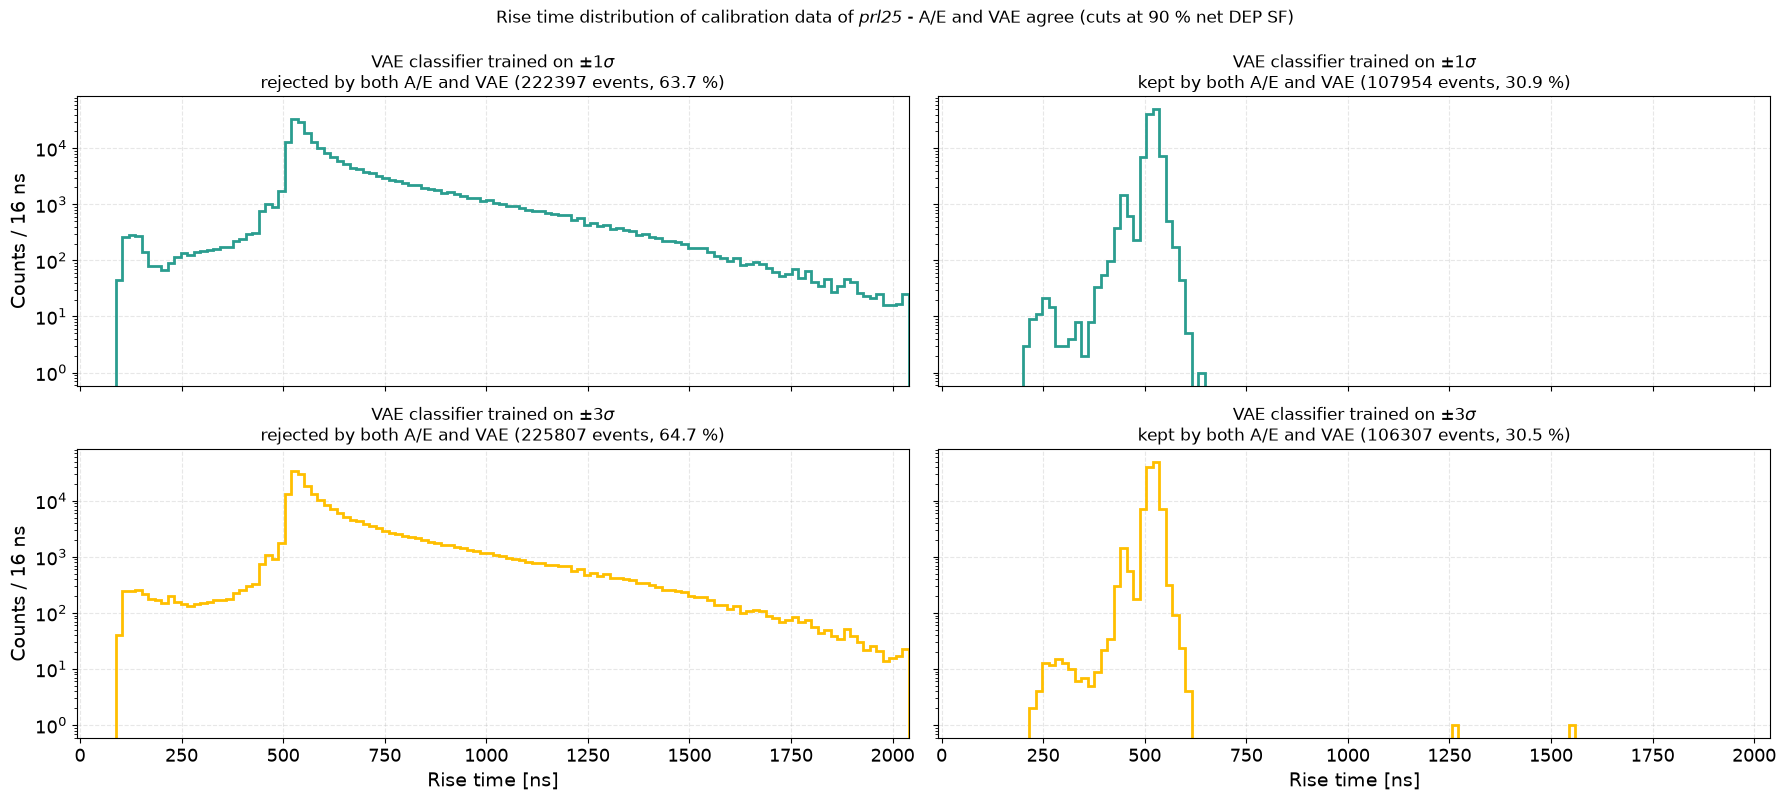

In [52]:
def plot_var_grid(values, bins, xlabel, ylabel, panels_of, suptitle, savepath, vlines=(), log=True, fill=False):
    fig, axes = plt.subplots(len(VAE_SIGMAS), 2, figsize=(18, 4 * len(VAE_SIGMAS)), sharex=True, sharey=True, squeeze=False)
    handles = []
    for row, s in enumerate(VAE_SIGMAS):
        for col, (mask, color, lab) in enumerate(panels_of(s, kept[s])):
            ax = axes[row, col]
            v = values[mask]
            h, _ = np.histogram(v[np.isfinite(v)], bins=bins)
            if fill:
                ax.stairs(h, bins, fill=True, color=color, alpha=0.5)
                ax.stairs(h, bins, color=color, lw=1)
            else:
                ax.stairs(h, bins, color=color, lw=2)
            handles = [ax.axvline(x, color=c, ls='--', lw=2, label=l) for x, c, l in vlines]
            ax.set_title(f"{vae_title(s)}\n{lab} ({mask.sum()} events, {mask.mean()*100:.1f} %)")
            if log:
                ax.set_yscale('log')
            ax.set_xlim(bins[0], bins[-1])
            ax.grid(alpha=0.3, ls='--')
            ax.set_axisbelow(True)
        axes[row, 0].set_ylabel(ylabel)
    for ax in axes[-1]:
        ax.set_xlabel(xlabel)
    fig.suptitle(suptitle, y=0.995)
    if handles:
        fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=len(handles), frameon=False, fontsize=11)
    fig.tight_layout(rect=[0, 0, 1, 0.98 if handles else 1])
    fig.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


dep_fep_lines = [(DEP_MU, pf.color4, r"DEP of ${}^{208}$Tl"), (FEP_MU, pf.color5, r"FEP of ${}^{212}$Bi")]
lo, hi = np.nanquantile(aoe_val, [0.001, 0.999])
VARIABLES = [   # values, bins, xlabel, ylabel, name, file tag, options
    (energy,  FIT_BINS, "Energy [keV]", "Counts / keV", "Energy distribution", "energy", dict(fill=True, vlines=dep_fep_lines)),
    (aoe_val, np.linspace(lo, hi, N_BINS_AOE + 1), "A/E", "Counts / bin", "A/E distribution", "AoE", {}),
    (rt_val,  np.arange(-RT_BIN / 2, np.nanquantile(rt_val, 0.999) + RT_BIN, RT_BIN), "Rise time [ns]",
     f"Counts / {RT_BIN} ns", "Rise time distribution", "risetime", {}),
]

for values, b, xlabel, ylabel, name, ftag, opts in VARIABLES:
    for panels_of, what in ((disagree, 'disagree'), (agree, 'agree')):
        plot_var_grid(values, b, xlabel, ylabel, panels_of,
                      rf"{name} of calibration data of $\mathit{{prl25}}$ - A/E and VAE {what} {wp}",
                      os.path.join(LEAN_DIR, f'{ftag}_{what}.pdf'), **opts)

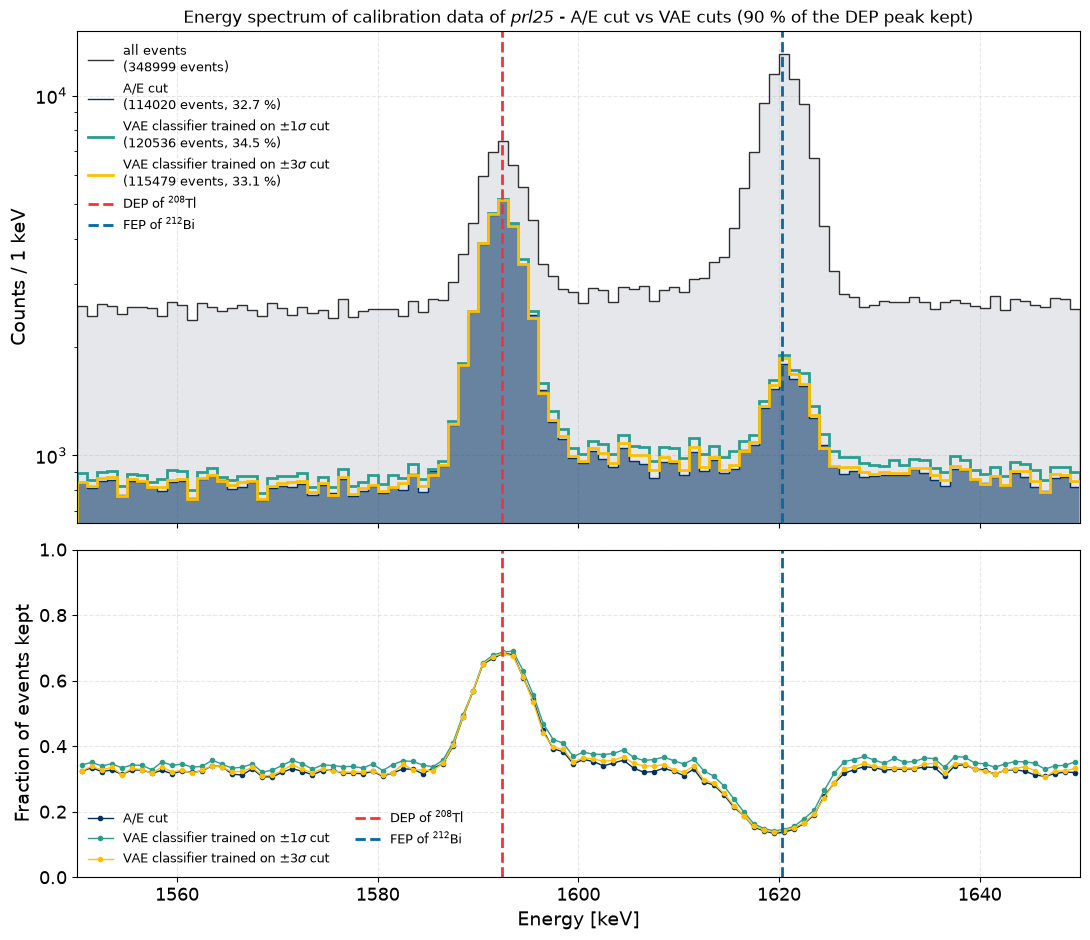

In [53]:
VAE_SIGMAS       = [1, 3]

# energy spectrum after the cuts at DEP_TARGET (A/E recomputed and VAE classifiers) and fraction of events kept per keV
fig, (ax, axf) = plt.subplots(2, 1, figsize=(11, 9.5), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
h_tot, _ = np.histogram(energy, bins=FIT_BINS)
centres = 0.5 * (FIT_BINS[:-1] + FIT_BINS[1:])

cuts = [('A/E cut', a_cut, pf.color2)] + [(f"{vae_title(s)} cut", kept[s], vae_color(s)) for s in VAE_SIGMAS]

# ---------------- top: spectra ----------------
ax.stairs(h_tot, FIT_BINS, fill=True, color=pf.color1, alpha=0.3)
ax.stairs(h_tot, FIT_BINS, color='black', alpha=0.8, lw=1, label=f"all events\n({len(energy)} events)")
for i, (lab, mask, color) in enumerate(cuts):
    h_cut, _ = np.histogram(energy[mask], bins=FIT_BINS)
    text = f"{lab}\n({mask.sum()} events, {100 * mask.mean():.1f} %)"
    if i == 0:   # A/E filled, as in the DTC plot
        ax.stairs(h_cut, FIT_BINS, fill=True, color=color, alpha=0.55)
        ax.stairs(h_cut, FIT_BINS, color=color, lw=1, label=text)
    else:
        ax.stairs(h_cut, FIT_BINS, color=color, lw=2, label=text)
    with np.errstate(divide='ignore', invalid='ignore'):
        axf.plot(centres, h_cut / h_tot, color=color, marker='o', ms=3, lw=1, label=lab)

for a in (ax, axf):
    a.axvline(DEP_MU, color=pf.color4, ls='--', lw=2, label=r"DEP of ${}^{208}$Tl")
    a.axvline(FEP_MU, color=pf.color5, ls='--', lw=2, label=r"FEP of ${}^{212}$Bi")
    a.grid(alpha=0.3, ls='--')
    a.set_axisbelow(True)

ax.set_yscale('log')
ax.set_ylabel('Counts / 1 keV')
ax.legend(frameon=False, loc='upper left', fontsize=9)
ax.set_title(rf"Energy spectrum of calibration data of $\mathit{{prl25}}$ - A/E cut vs VAE cuts "
             f"({100*DEP_TARGET:.0f} % of the DEP peak kept)")

# ---------------- bottom: fraction of events kept ----------------
axf.set_ylim(0, 1)
axf.set_xlim(E_MIN, E_MAX)
axf.set_xlabel('Energy [keV]')
axf.set_ylabel('Fraction of events kept')
axf.legend(frameon=False, loc='lower left', fontsize=9, ncol=2)

fig.tight_layout()
fig.savefig(os.path.join(LEAN_DIR, 'spectrum_cuts_VAE.pdf'), dpi=300)
plt.show()